# Comparación de estrategias de segmentación pulmonar y extracción radiómica

Este cuaderno integra la preparación de datos y el modelo Mask2Former ya desarrollado, y añade dos métodos clásicos para compararlos: **umbralización de Otsu con operaciones morfológicas** y **contornos activos (Active Contour)**.

El flujo de comparación utiliza las mismas radiografías originales para los tres métodos. Cada método genera una máscara binaria; después se comparan las máscaras con la referencia mediante Dice e IoU y se extraen características de primer orden sobre la misma radiografía.

**Importante:** los métodos clásicos son líneas base exploratorias. Otsu separa intensidades y no reconoce anatomía; los contornos activos necesitan una inicialización aproximada. Sus resultados deben inspeccionarse visualmente y no deben interpretarse como segmentaciones clínicamente validadas.

**Uso del modelo existente:** si solo se desea comparar las técnicas con el Mask2Former ya entrenado, se pueden omitir los bloques de entrenamiento y guardado (bloques 1 a 4 de entrenamiento) y ejecutar desde la inferencia, siempre que la carpeta `mejor_modelo_validacion` exista en Drive.


**Alcance de la comparación:** las métricas Dice/IoU evalúan la similitud con las máscaras binarias de referencia. Las características radiómicas se calculan sobre la imagen original en escala de grises, no sobre los valores de la máscara. En la comparación global, Mask2Former se evalúa usando la unión de sus instancias para mantener el mismo nivel de análisis que los dos métodos clásicos.


## 1. Verificación inicial de GPU



In [1]:
!nvidia-smi

Thu Nov 12 18:15:24 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   38C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Información de PyTorch y GPU



In [2]:
import torch

print("Versión de PyTorch:", torch.__version__)
print("CUDA disponible:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("Memoria GPU (GB):",
          round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2))

    dispositivo = torch.device("cuda")
    prueba = torch.rand(100, 100, device=dispositivo)

    print("Prueba de cálculo en GPU:", prueba.device)

Versión de PyTorch: 2.14.1+cpu
CUDA disponible: False


## 3. Verificación de bibliotecas



In [3]:
# ============================================================
# PASO 3. VERIFICACIÓN DE BIBLIOTECAS
# Proyecto: Segmentación pulmonar con Mask2Former
# ============================================================

# Importamos una herramienta de Python que permite comprobar
# si una biblioteca está instalada, sin modificar el entorno.
import importlib.util

# Comprobamos si Hugging Face Transformers está instalado.
# Esta biblioteca incluye una implementación de Mask2Former.
print("Transformers instalado:",
      importlib.util.find_spec("transformers") is not None)

# Comprobamos si Torchvision está instalado.
# Proporciona herramientas para trabajar con imágenes.
print("Torchvision instalado:",
      importlib.util.find_spec("torchvision") is not None)

# Comprobamos si Accelerate está instalado.
# Facilita la ejecución y el entrenamiento de modelos
# de aprendizaje profundo en CPU y GPU.
print("Accelerate instalado:",
      importlib.util.find_spec("accelerate") is not None)

# Active Contour utiliza la biblioteca scikit-image.
# La instalamos únicamente si no está disponible en el entorno.
if importlib.util.find_spec("skimage") is None:
    print("Instalando scikit-image para Active Contour...")
    import subprocess
    import sys
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "scikit-image"
    ])

print("scikit-image instalado:",
      importlib.util.find_spec("skimage") is not None)


Transformers instalado: True
Torchvision instalado: True
Accelerate instalado: True
scikit-image instalado: True


## 4. Verificación de Mask2Former



In [4]:
# ============================================================
# PASO 4. VERIFICACIÓN DE MASK2FORMER
# Proyecto: Segmentación pulmonar
# ============================================================

# Importamos la biblioteca Transformers.
import transformers

# Mostramos la versión instalada.
print("Versión de Transformers:", transformers.__version__)

# Intentamos importar los componentes de Mask2Former.
# Mask2FormerConfig: define la configuración del modelo.
# Mask2FormerForUniversalSegmentation: arquitectura de
# segmentación que utilizaremos en nuestro proyecto.
# Mask2FormerImageProcessor: prepara imágenes y máscaras.

try:
    from transformers import (
        Mask2FormerConfig,
        Mask2FormerForUniversalSegmentation,
        Mask2FormerImageProcessor
    )

    print("Mask2Former importado correctamente.")
    print("La arquitectura está disponible.")

except Exception as error:
    print("No se pudo importar Mask2Former.")
    print("Tipo de error:", type(error).__name__)
    print("Detalle:", error)

Versión de Transformers: 5.22.1
Mask2Former importado correctamente.
La arquitectura está disponible.


## 5. Conexión con Google Drive



In [5]:
# ============================================================
# PASO 6. CONEXIÓN CON GOOGLE DRIVE
# Proyecto: Segmentación pulmonar con Mask2Former
# ============================================================

# Importamos la herramienta para conectar Google Drive.
from google.colab import drive

# Conectamos nuestro Drive con el entorno de Google Colab.
# Al ejecutar esta instrucción, aparecerá una solicitud
# para autorizar el acceso a nuestra unidad.
drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
# ============================================================
# COMPROBACIÓN. VERIFICAR QUE GOOGLE DRIVE ESTÁ DISPONIBLE
# ============================================================

from pathlib import Path

# Esta es la carpeta persistente del proyecto en Google Drive.
ruta_base_modelo = Path("/content/drive/MyDrive/Mask2Former_Pulmonar")

# Comprobar que Drive está montado antes de buscar o guardar archivos.
ruta_mi_unidad = Path("/content/drive/MyDrive")
print("¿Google Drive está disponible?:", ruta_mi_unidad.exists())

if not ruta_mi_unidad.exists():
    raise RuntimeError(
        "Google Drive no está montado. Ejecuta primero la celda drive.mount('/content/drive')."
    )

# Mostrar el contenido existente sin borrar ni modificar archivos.
print("\nCarpeta del proyecto:", ruta_base_modelo)
if ruta_base_modelo.exists():
    for elemento in sorted(ruta_base_modelo.iterdir()):
        tipo = "Carpeta" if elemento.is_dir() else "Archivo"
        print(f"{tipo}: {elemento.name}")
else:
    print("La carpeta del proyecto todavía no existe en Drive.")

# Buscar los archivos principales de pesos en la carpeta del proyecto.
if ruta_base_modelo.exists():
    archivos_pesos = list(ruta_base_modelo.rglob("model.safetensors"))
    archivos_binarios = list(ruta_base_modelo.rglob("pytorch_model.bin"))
    encontrados = archivos_pesos + archivos_binarios
    print("\nArchivos de pesos encontrados:", len(encontrados))
    for archivo in encontrados:
        print(" -", archivo)


¿Google Drive está disponible?: True

Carpeta del proyecto: /content/drive/MyDrive/Mask2Former_Pulmonar
Archivo: config.json
Archivo: historial_entrenamiento.csv
Carpeta: mascaras_predichas
Carpeta: mejor_modelo_validacion
Archivo: model.safetensors
Archivo: preprocessor_config.json
Carpeta: resultados_instancias
Carpeta: resultados_radiomicos

Archivos de pesos encontrados: 2
 - /content/drive/MyDrive/Mask2Former_Pulmonar/model.safetensors
 - /content/drive/MyDrive/Mask2Former_Pulmonar/mejor_modelo_validacion/model.safetensors


## 6. Extracción del dataset



In [7]:
# ============================================================
# PASO 8. DESCOMPRESIÓN DEL DATASET
# Proyecto: Segmentación pulmonar con Mask2Former
# ============================================================

# Importamos las bibliotecas necesarias para manejar
# archivos, carpetas y archivos comprimidos.
import os
import zipfile
import shutil

# Definimos la ruta del archivo ZIP almacenado en Google Drive.
ruta_zip = "/content/drive/MyDrive/archive.zip"

# Definimos la carpeta de Colab donde se extraerá el dataset.
ruta_dataset = "/content/dataset"

# Verificamos que el archivo ZIP exista antes de continuar.
if not os.path.isfile(ruta_zip):
    raise FileNotFoundError(
        f"No se encontró el archivo ZIP: {ruta_zip}"
    )

# Consultamos cuánto espacio libre tiene Colab.
espacio_libre = shutil.disk_usage("/content").free

# Abrimos el ZIP para calcular el tamaño de los archivos
# una vez descomprimidos, sin extraerlos todavía.
with zipfile.ZipFile(ruta_zip, "r") as archivo_zip:

    tamaño_descomprimido = sum(
        archivo.file_size
        for archivo in archivo_zip.infolist()
        if not archivo.is_dir()
    )

    print(
        "Tamaño descomprimido:",
        round(tamaño_descomprimido / (1024**3), 2),
        "GB"
    )

    print(
        "Espacio libre:",
        round(espacio_libre / (1024**3), 2),
        "GB"
    )

    # Dejamos un margen de seguridad de 5 GB
    # para evitar llenar el almacenamiento temporal.
    margen_seguridad = 5 * (1024**3)

    if tamaño_descomprimido + margen_seguridad > espacio_libre:
        raise RuntimeError(
            "No hay suficiente espacio libre para extraer el dataset."
        )

    # Creamos la carpeta de destino si no existe.
    os.makedirs(ruta_dataset, exist_ok=True)

    # Extraemos los archivos conservando su estructura original.
    archivo_zip.extractall(ruta_dataset)

# Definimos las rutas reales de las imágenes y las máscaras.
ruta_imagenes = os.path.join(
    ruta_dataset, "Chest-X-Ray", "Chest-X-Ray", "image"
)

ruta_mascaras = os.path.join(
    ruta_dataset, "Chest-X-Ray", "Chest-X-Ray", "mask"
)

# Verificamos que ambas carpetas se hayan creado.
if not os.path.isdir(ruta_imagenes):
    raise FileNotFoundError(
        f"No se encontró la carpeta de imágenes: {ruta_imagenes}"
    )

if not os.path.isdir(ruta_mascaras):
    raise FileNotFoundError(
        f"No se encontró la carpeta de máscaras: {ruta_mascaras}"
    )

# Contamos únicamente los archivos PNG de cada carpeta.
cantidad_imagenes = len([
    archivo for archivo in os.listdir(ruta_imagenes)
    if archivo.lower().endswith(".png")
])

cantidad_mascaras = len([
    archivo for archivo in os.listdir(ruta_mascaras)
    if archivo.lower().endswith(".png")
])

# Mostramos el resultado final.
print("\nDATASET DESCOMPRIMIDO CORRECTAMENTE")
print("Ruta de las radiografías:", ruta_imagenes)
print("Ruta de las máscaras:", ruta_mascaras)
print("Cantidad de radiografías:", cantidad_imagenes)
print("Cantidad de máscaras:", cantidad_mascaras)

Tamaño descomprimido: 3.6 GB
Espacio libre: 107.57 GB

DATASET DESCOMPRIMIDO CORRECTAMENTE
Ruta de las radiografías: /content/dataset/Chest-X-Ray/Chest-X-Ray/image
Ruta de las máscaras: /content/dataset/Chest-X-Ray/Chest-X-Ray/mask
Cantidad de radiografías: 704
Cantidad de máscaras: 704


## 7. Identificación de instancias en las máscaras reales



Dimensiones de la radiografía: (2995, 2993)
Dimensiones de la máscara: (2995, 2993)
Regiones blancas detectadas: 2

Regiones seleccionadas:
Instancia 1: 933510 píxeles
Instancia 2: 856079 píxeles


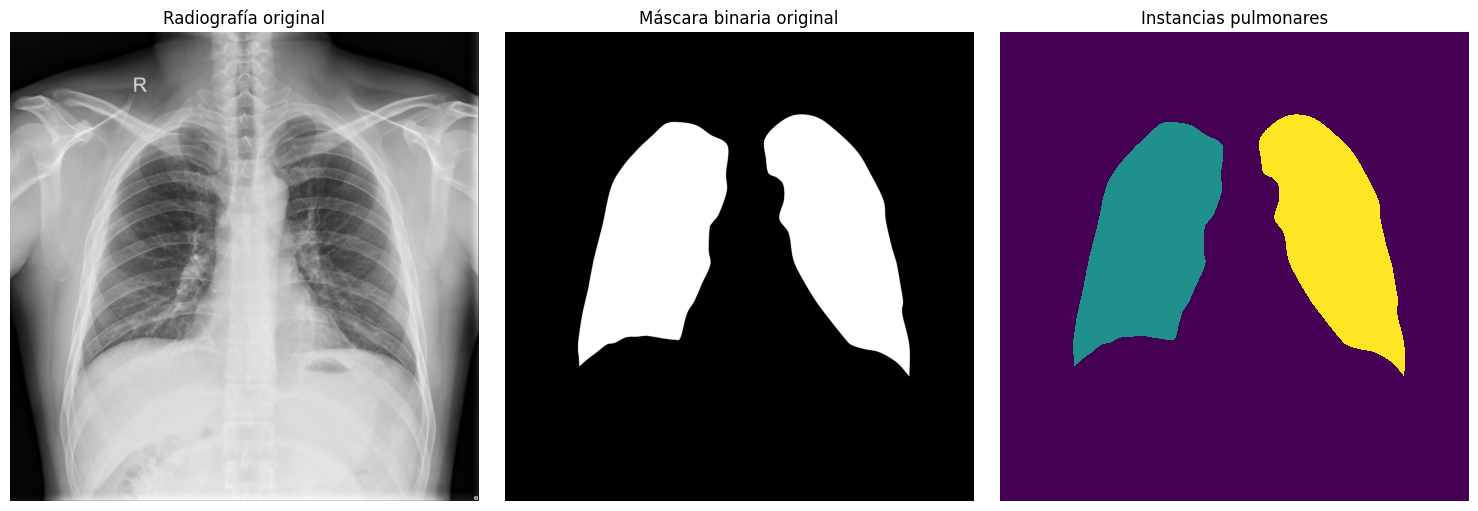

In [8]:
# ============================================================
# PASO 9. IDENTIFICACIÓN DE INSTANCIAS PULMONARES
# Proyecto: Segmentación pulmonar por instancia con Mask2Former
# ============================================================

# Importamos las bibliotecas necesarias.
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage

# Definimos las rutas de la radiografía y su máscara.
ruta_imagen = Path(
    "/content/dataset/Chest-X-Ray/Chest-X-Ray/image/1000.png"
)

ruta_mascara = Path(
    "/content/dataset/Chest-X-Ray/Chest-X-Ray/mask/1000.png"
)

# Comprobamos que ambos archivos existan.
if not ruta_imagen.exists():
    raise FileNotFoundError(f"No existe la radiografía: {ruta_imagen}")

if not ruta_mascara.exists():
    raise FileNotFoundError(f"No existe la máscara: {ruta_mascara}")

# Cargamos la radiografía en escala de grises.
imagen = np.array(Image.open(ruta_imagen).convert("L"))

# Cargamos la máscara original en escala de grises.
mascara = np.array(Image.open(ruta_mascara).convert("L"))

# Convertimos los píxeles blancos en True y los negros en False.
# Esto permite identificar qué píxeles pertenecen a los pulmones.
mascara_binaria = mascara > 0

# Definimos conectividad 8:
# dos píxeles se consideran conectados incluso diagonalmente.
estructura = np.ones((3, 3), dtype=np.uint8)

# Identificamos cada región blanca conectada.
etiquetas, numero_regiones = ndimage.label(
    mascara_binaria,
    structure=estructura
)

# Contamos cuántos píxeles contiene cada región detectada.
tamaños = np.bincount(etiquetas.ravel())

# Excluimos la etiqueta 0, que representa el fondo.
identificadores = np.arange(1, numero_regiones + 1)

# Ordenamos las regiones desde la más grande hasta la más pequeña.
regiones_ordenadas = sorted(
    identificadores,
    key=lambda identificador: tamaños[identificador],
    reverse=True
)

# Creamos una máscara de instancias inicializada en cero.
# Valor 0: fondo.
mascara_instancias = np.zeros(
    mascara.shape,
    dtype=np.uint8
)

# Seleccionamos provisionalmente las dos regiones más grandes.
# Esta selección se debe comprobar visualmente.
for nueva_etiqueta, identificador in enumerate(
    regiones_ordenadas[:2],
    start=1
):
    mascara_instancias[etiquetas == identificador] = nueva_etiqueta

# Mostramos información de las regiones encontradas.
print("Dimensiones de la radiografía:", imagen.shape)
print("Dimensiones de la máscara:", mascara.shape)
print("Regiones blancas detectadas:", numero_regiones)

print("\nRegiones seleccionadas:")
for nueva_etiqueta, identificador in enumerate(
    regiones_ordenadas[:2],
    start=1
):
    print(
        f"Instancia {nueva_etiqueta}: "
        f"{tamaños[identificador]} píxeles"
    )

# Visualizamos la radiografía, la máscara binaria original
# y la máscara de instancias obtenida.
fig, ejes = plt.subplots(1, 3, figsize=(15, 5))

ejes[0].imshow(imagen, cmap="gray")
ejes[0].set_title("Radiografía original")

ejes[1].imshow(mascara_binaria, cmap="gray")
ejes[1].set_title("Máscara binaria original")

# Usamos colores distintos para visualizar las dos instancias.
ejes[2].imshow(
    mascara_instancias,
    cmap="viridis",
    vmin=0,
    vmax=2,
    interpolation="nearest"
)
ejes[2].set_title("Instancias pulmonares")

# Ocultamos los ejes para observar mejor las imágenes.
for eje in ejes:
    eje.axis("off")

plt.tight_layout()
plt.show()

## 8. Revisión de componentes de las máscaras



In [10]:
# ============================================================
# PASO 10. EVALUACIÓN DE LAS 704 MÁSCARAS PULMONARES
# Proyecto: Segmentación por instancia con Mask2Former
# ============================================================

# Importamos las bibliotecas necesarias.
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image
from scipy import ndimage

# Definimos la carpeta que contiene las máscaras originales.
ruta_mascaras = Path(
    "/content/dataset/Chest-X-Ray/Chest-X-Ray/mask"
)

# Obtenemos todos los archivos PNG de la carpeta.
archivos_mascaras = sorted(ruta_mascaras.glob("*.png"))

# Creamos una lista para guardar los resultados del análisis.
resultados = []

# Definimos la conectividad 8 para identificar regiones.
estructura = np.ones((3, 3), dtype=np.uint8)

# Recorremos cada una de las máscaras del dataset.
for archivo in archivos_mascaras:

    # Abrimos la máscara en escala de grises.
    mascara = np.array(
        Image.open(archivo).convert("L")
    )

    # Identificamos los píxeles que pertenecen a los pulmones.
    mascara_binaria = mascara > 0

    # Detectamos las regiones blancas conectadas.
    etiquetas, numero_regiones = ndimage.label(
        mascara_binaria,
        structure=estructura
    )

    # Calculamos el tamaño de cada región detectada.
    tamaños = np.bincount(etiquetas.ravel())[1:]

    # Ordenamos los tamaños de mayor a menor.
    tamaños_ordenados = np.sort(tamaños)[::-1]

    # Obtenemos los tamaños de las dos regiones más grandes.
    tamaño_primera = (
        int(tamaños_ordenados[0])
        if len(tamaños_ordenados) >= 1
        else 0
    )

    tamaño_segunda = (
        int(tamaños_ordenados[1])
        if len(tamaños_ordenados) >= 2
        else 0
    )

    # Calculamos cuántos píxeles blancos quedarían fuera
    # si conserváramos solamente las dos regiones más grandes.
    pixeles_fuera = int(
        tamaños_ordenados[2:].sum()
    )

    # Guardamos la información de esta máscara.
    resultados.append({
        "archivo": archivo.name,
        "numero_regiones": numero_regiones,
        "pixeles_primera_region": tamaño_primera,
        "pixeles_segunda_region": tamaño_segunda,
        "pixeles_fuera_dos_regiones": pixeles_fuera
    })

# Convertimos los resultados en un DataFrame.
df_regiones = pd.DataFrame(resultados)

# Mostramos el número total de máscaras analizadas.
print("MÁSCARAS ANALIZADAS:", len(df_regiones))

# Contamos las máscaras según su número de regiones.
print("\nDISTRIBUCIÓN DEL NÚMERO DE REGIONES:")
print(
    df_regiones["numero_regiones"]
    .value_counts()
    .sort_index()
)

# Calculamos cuántas máscaras tienen exactamente dos regiones.
exactamente_dos = (
    df_regiones["numero_regiones"] == 2
).sum()

# Calculamos cuántas máscaras tienen menos de dos regiones.
menos_de_dos = (
    df_regiones["numero_regiones"] < 2
).sum()

# Calculamos cuántas máscaras tienen más de dos regiones.
mas_de_dos = (
    df_regiones["numero_regiones"] > 2
).sum()

# Mostramos un resumen general.
print("\nRESUMEN GENERAL")
print("Exactamente dos regiones:", exactamente_dos)
print("Menos de dos regiones:", menos_de_dos)
print("Más de dos regiones:", mas_de_dos)

# Mostramos las primeras 10 máscaras que necesitan revisión.
# Tener más de dos regiones no significa necesariamente que
# la máscara sea incorrecta; puede contener fragmentos pequeños.
mascaras_revision = df_regiones[
    df_regiones["numero_regiones"] != 2
]

print("\nPRIMERAS 10 MÁSCARAS PARA REVISIÓN:")
print(mascaras_revision.head(10).to_string(index=False))

MÁSCARAS ANALIZADAS: 704

DISTRIBUCIÓN DEL NÚMERO DE REGIONES:
numero_regiones
2     598
3      66
4      18
5       6
6       6
7       3
8       3
9       1
12      1
14      1
15      1
Name: count, dtype: int64

RESUMEN GENERAL
Exactamente dos regiones: 598
Menos de dos regiones: 0
Más de dos regiones: 106

PRIMERAS 10 MÁSCARAS PARA REVISIÓN:
 archivo  numero_regiones  pixeles_primera_region  pixeles_segunda_region  pixeles_fuera_dos_regiones
1015.png                7                 1415421                 1153536                           7
1016.png                3                  792187                  686828                           9
1021.png                9                  779974                  694132                          16
1023.png                3                 1274139                 1145281                           5
1035.png                3                 1036976                  880196                           1
1043.png                4              

## 9. Generación de máscaras por instancia



In [11]:
# ============================================================
# PASO 11. GENERACIÓN RÁPIDA DE MÁSCARAS DE INSTANCIA
# ============================================================
# Objetivo:
# Convertir cada máscara binaria en una máscara de instancia:
#   0 = fondo
#   1 = pulmón situado a la izquierda de la imagen
#   2 = pulmón situado a la derecha de la imagen
#
# Estrategia:
# 1. Detectar las regiones blancas conectadas.
# 2. Seleccionar las dos regiones más grandes como pulmones.
# 3. Ordenarlas por su posición horizontal en la imagen.
# 4. Asignar los fragmentos pequeños al pulmón cuyo centroide
#    esté más cerca.
#
# Importante:
# La asignación de fragmentos es una aproximación automática.
# Se debe validar visualmente antes de entrenar Mask2Former.
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image
from scipy import ndimage
from tqdm.auto import tqdm

# ------------------------------------------------------------
# 1. Definir las carpetas de entrada y salida
# ------------------------------------------------------------

carpeta_mascaras = Path(
    "/content/dataset/Chest-X-Ray/Chest-X-Ray/mask"
)

carpeta_instancias = Path(
    "/content/dataset/instance_masks"
)

# Crear la carpeta de salida si todavía no existe.
carpeta_instancias.mkdir(parents=True, exist_ok=True)

# Buscar las máscaras PNG originales.
archivos_mascaras = sorted(carpeta_mascaras.glob("*.png"))

print("Máscaras encontradas:", len(archivos_mascaras))

if len(archivos_mascaras) == 0:
    raise FileNotFoundError(
        "No se encontraron máscaras PNG en la carpeta de entrada."
    )

# ------------------------------------------------------------
# 2. Definir la conectividad entre píxeles
# ------------------------------------------------------------

# La conectividad 8 considera vecinos horizontales, verticales
# y diagonales como parte de una misma región.
estructura = np.ones((3, 3), dtype=np.uint8)

# Aquí se guardará el resultado del procesamiento de cada archivo.
resultados = []

# ------------------------------------------------------------
# 3. Procesar cada máscara
# ------------------------------------------------------------

for ruta_mascara in tqdm(
    archivos_mascaras,
    desc="Generando máscaras de instancia"
):
    # Leer la máscara original en escala de grises.
    mascara_original = np.array(
        Image.open(ruta_mascara).convert("L")
    )

    # Convertir la máscara en una imagen binaria:
    # False = fondo; True = región pulmonar.
    mascara_binaria = mascara_original > 0

    # Identificar las regiones blancas conectadas.
    etiquetas, numero_regiones = ndimage.label(
        mascara_binaria,
        structure=estructura
    )

    # Contar cuántos píxeles tiene cada región.
    # El índice 0 corresponde al fondo.
    cantidades = np.bincount(etiquetas.ravel())

    # Excluir el fondo y conservar las regiones detectadas.
    ids_regiones = np.arange(1, numero_regiones + 1)

    if len(ids_regiones) < 2:
        # No es posible separar dos pulmones si solo se detecta
        # una región conectada. Registrar el caso para revisarlo.
        resultados.append({
            "archivo": ruta_mascara.name,
            "regiones_detectadas": int(numero_regiones),
            "estado": "REVISAR: menos de dos regiones",
            "pixeles_instancia_1": 0,
            "pixeles_instancia_2": 0
        })
        continue

    # Obtener los índices de las dos regiones con más píxeles.
    ids_mayores = ids_regiones[
        np.argsort(cantidades[ids_regiones])[-2:]
    ]

    # Calcular los centroides de las dos regiones principales.
    # El resultado de center_of_mass utiliza el orden (fila, columna).
    centroides = ndimage.center_of_mass(
        mascara_binaria,
        etiquetas,
        ids_mayores.tolist()
    )

    # Ordenar los dos pulmones según su posición horizontal:
    # menor columna = izquierda de la imagen;
    # mayor columna = derecha de la imagen.
    orden = np.argsort([centro[1] for centro in centroides])

    id_izquierda = int(ids_mayores[orden[0]])
    id_derecha = int(ids_mayores[orden[1]])

    centro_izquierda = centroides[orden[0]]
    centro_derecha = centroides[orden[1]]

    # Crear la máscara de instancia.
    # Inicialmente, todos los píxeles pertenecen al fondo.
    mascara_instancia = np.zeros(
        etiquetas.shape,
        dtype=np.uint8
    )

    # Asignar las dos regiones principales a instancias distintas.
    mascara_instancia[etiquetas == id_izquierda] = 1
    mascara_instancia[etiquetas == id_derecha] = 2

    # --------------------------------------------------------
    # 4. Asignar las regiones pequeñas a uno de los pulmones
    # --------------------------------------------------------

    # Buscar las regiones que no son ninguna de las dos principales.
    ids_pequenos = [
        int(id_region)
        for id_region in ids_regiones
        if id_region not in (id_izquierda, id_derecha)
    ]

    # Obtener los límites espaciales de las regiones conectadas.
    # Esto permite calcular el centro de cada fragmento usando
    # solamente su recorte, en lugar de recorrer toda la imagen.
    cajas = ndimage.find_objects(etiquetas)

    for id_region in ids_pequenos:
        caja = cajas[id_region - 1]

        if caja is None:
            continue

        # Recortar la zona donde está el fragmento.
        recorte = etiquetas[caja]

        # Localizar los píxeles que pertenecen al fragmento.
        filas, columnas = np.nonzero(recorte == id_region)

        if len(filas) == 0:
            continue

        # Calcular el centro del fragmento en coordenadas globales.
        centro_fila = caja[0].start + filas.mean()
        centro_columna = caja[1].start + columnas.mean()

        # Calcular la distancia al centro de cada pulmón.
        distancia_izquierda = (
            (centro_fila - centro_izquierda[0]) ** 2
            + (centro_columna - centro_izquierda[1]) ** 2
        )

        distancia_derecha = (
            (centro_fila - centro_derecha[0]) ** 2
            + (centro_columna - centro_derecha[1]) ** 2
        )

        # Asignar el fragmento al pulmón con el centroide más cercano.
        instancia_asignada = (
            1 if distancia_izquierda <= distancia_derecha else 2
        )

        mascara_instancia[etiquetas == id_region] = instancia_asignada

    # --------------------------------------------------------
    # 5. Guardar la máscara de instancia
    # --------------------------------------------------------

    ruta_salida = carpeta_instancias / ruta_mascara.name

    Image.fromarray(mascara_instancia).save(ruta_salida)

    # Registrar información para revisar los resultados.
    resultados.append({
        "archivo": ruta_mascara.name,
        "regiones_detectadas": int(numero_regiones),
        "estado": "Procesada",
        "pixeles_instancia_1": int(
            np.count_nonzero(mascara_instancia == 1)
        ),
        "pixeles_instancia_2": int(
            np.count_nonzero(mascara_instancia == 2)
        )
    })

# ------------------------------------------------------------
# 6. Guardar el informe de procesamiento
# ------------------------------------------------------------

informe = pd.DataFrame(resultados)

ruta_informe = carpeta_instancias / "informe_instancias.csv"
informe.to_csv(ruta_informe, index=False)

# ------------------------------------------------------------
# 7. Mostrar el resumen final
# ------------------------------------------------------------

procesadas = (informe["estado"] == "Procesada").sum()
pendientes = len(informe) - procesadas

print("\nPROCESAMIENTO TERMINADO")
print("-----------------------")
print("Máscaras originales:", len(archivos_mascaras))
print("Máscaras procesadas:", int(procesadas))
print("Máscaras para revisar:", int(pendientes))
print("Carpeta de salida:", carpeta_instancias)
print("Informe guardado en:", ruta_informe)

# Mostrar los casos que necesitan revisión, si existen.
if pendientes > 0:
    print("\nArchivos que requieren revisión:")
    display(informe[informe["estado"] != "Procesada"])

Máscaras encontradas: 704


Generando máscaras de instancia:   0%|          | 0/704 [00:00<?, ?it/s]


PROCESAMIENTO TERMINADO
-----------------------
Máscaras originales: 704
Máscaras procesadas: 704
Máscaras para revisar: 0
Carpeta de salida: /content/dataset/instance_masks
Informe guardado en: /content/dataset/instance_masks/informe_instancias.csv


## 10. Validación visual de las instancias



1000.png valores de píxel: [0 1 2]
1015.png valores de píxel: [0 1 2]


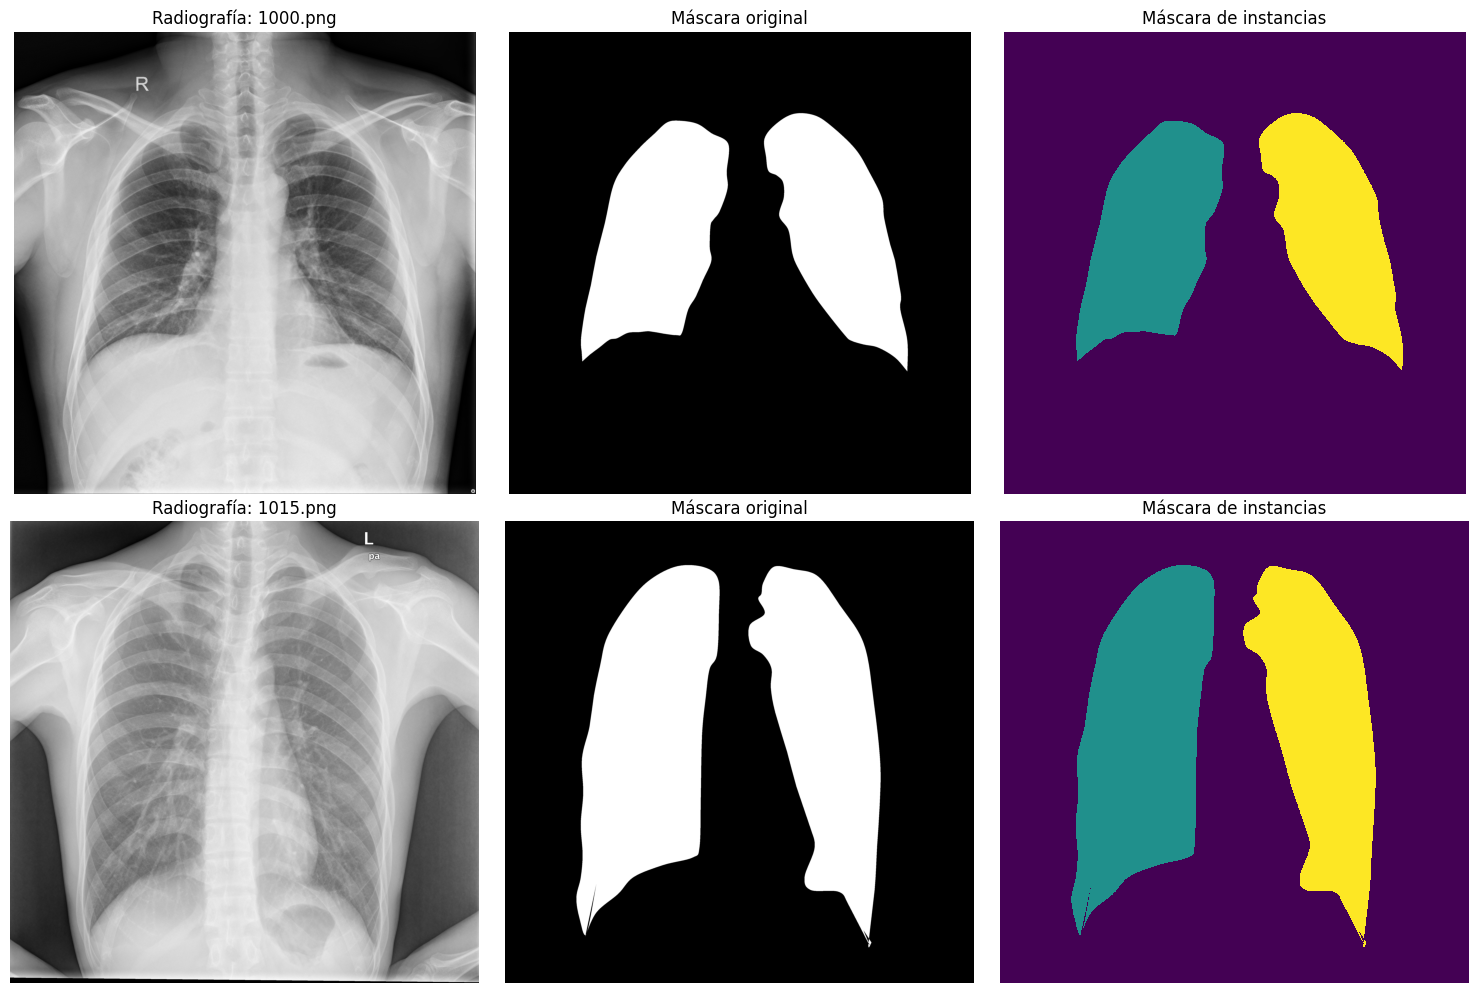

In [12]:
# ============================================================
# PASO 12. VALIDACIÓN VISUAL DE LAS INSTANCIAS
# ============================================================

# Importamos las bibliotecas necesarias para visualizar.
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

# Definimos las rutas de las imágenes y las máscaras.
carpeta_imagenes = Path(
    "/content/dataset/Chest-X-Ray/Chest-X-Ray/image"
)

carpeta_mascaras = Path(
    "/content/dataset/Chest-X-Ray/Chest-X-Ray/mask"
)

carpeta_instancias = Path(
    "/content/dataset/instance_masks"
)

# Seleccionamos un caso sencillo y uno con fragmentos.
ejemplos = ["1000.png", "1015.png"]

# Creamos una figura con tres columnas por cada ejemplo.
fig, ejes = plt.subplots(
    len(ejemplos), 3,
    figsize=(15, 10)
)

# Recorremos los dos ejemplos.
for fila, nombre in enumerate(ejemplos):

    # Cargamos la radiografía original.
    imagen = np.array(
        Image.open(carpeta_imagenes / nombre).convert("L")
    )

    # Cargamos la máscara binaria original.
    mascara = np.array(
        Image.open(carpeta_mascaras / nombre).convert("L")
    )

    # Cargamos la máscara de instancias generada.
    ruta_instancia = carpeta_instancias / nombre

    if not ruta_instancia.exists():
        print(
            f"No se generó la máscara de instancia para {nombre}"
        )
        continue

    instancias = np.array(
        Image.open(ruta_instancia)
    )

    # Mostramos la radiografía original.
    ejes[fila, 0].imshow(imagen, cmap="gray")
    ejes[fila, 0].set_title(f"Radiografía: {nombre}")

    # Mostramos la máscara binaria original.
    ejes[fila, 1].imshow(mascara, cmap="gray")
    ejes[fila, 1].set_title("Máscara original")

    # Mostramos las instancias con colores diferentes.
    ejes[fila, 2].imshow(
        instancias,
        cmap="viridis",
        vmin=0,
        vmax=2,
        interpolation="nearest"
    )
    ejes[fila, 2].set_title("Máscara de instancias")

    # Mostramos qué valores contiene la máscara generada.
    print(
        nombre,
        "valores de píxel:",
        np.unique(instancias)
    )

# Ocultamos los ejes para facilitar la inspección.
for eje in ejes.flat:
    eje.axis("off")

plt.tight_layout()
plt.show()

## 11. Preparación del dataset para entrenamiento



In [15]:
# ============================================================
# PASO 13. PREPARACIÓN DEL DATASET PARA MASK2FORMER
# Proyecto: Segmentación pulmonar por instancia
#
# OBJETIVOS:
# 1. Verificar la correspondencia entre radiografías y máscaras.
# 2. Dividir el dataset en entrenamiento y validación.
# 3. Configurar el procesador de Mask2Former.
# 4. Crear los objetos Dataset de PyTorch.
# 5. Verificar que cada muestra contenga dos instancias pulmonares.
#
# CODIFICACIÓN DE LAS MÁSCARAS:
#   0 = fondo
#   1 = primera instancia pulmonar
#   2 = segunda instancia pulmonar
#
# AMBAS INSTANCIAS PERTENECEN A LA CLASE SEMÁNTICA "pulmon".
# El objetivo es detectar dos objetos separados de esa clase.
# ============================================================


# ------------------------------------------------------------
# 1. IMPORTAR LAS BIBLIOTECAS
# ------------------------------------------------------------

# Path permite definir rutas de archivos y carpetas.
from pathlib import Path

# NumPy permite trabajar con las máscaras como matrices.
import numpy as np

# Pandas permite crear y guardar el manifiesto del dataset.
import pandas as pd

# PIL permite cargar las radiografías y las máscaras.
from PIL import Image

# PyTorch permite crear los conjuntos de datos.
import torch
from torch.utils.data import Dataset

# Transformers proporciona el procesador de Mask2Former.
from transformers import Mask2FormerImageProcessor


# ------------------------------------------------------------
# 2. DEFINIR LAS RUTAS DEL DATASET
# ------------------------------------------------------------

# Carpeta de las radiografías originales.
carpeta_imagenes = Path(
    "/content/dataset/Chest-X-Ray/Chest-X-Ray/image"
)

# Carpeta de las máscaras binarias originales.
carpeta_mascaras_originales = Path(
    "/content/dataset/Chest-X-Ray/Chest-X-Ray/mask"
)

# Carpeta de las máscaras de instancia generadas en el PASO 11.
carpeta_instancias = Path(
    "/content/dataset/instance_masks"
)

# Archivo donde guardaremos la división de los datos.
ruta_manifiesto = (
    carpeta_instancias
    / "manifiesto_entrenamiento_validacion.csv"
)


# ------------------------------------------------------------
# 3. COMPROBAR QUE EXISTAN LAS CARPETAS
# ------------------------------------------------------------

# Verificamos que las tres carpetas necesarias estén disponibles.
for carpeta in [
    carpeta_imagenes,
    carpeta_mascaras_originales,
    carpeta_instancias
]:
    if not carpeta.is_dir():
        raise FileNotFoundError(
            f"No se encontró la carpeta necesaria: {carpeta}"
        )

# Obtener los nombres de las radiografías.
nombres_imagenes = {
    archivo.name
    for archivo in carpeta_imagenes.glob("*.png")
}

# Obtener los nombres de las máscaras originales.
nombres_mascaras = {
    archivo.name
    for archivo in carpeta_mascaras_originales.glob("*.png")
}

# Obtener los nombres de las máscaras de instancia.
# Se excluyen los archivos CSV porque solo buscamos imágenes PNG.
nombres_instancias = {
    archivo.name
    for archivo in carpeta_instancias.glob("*.png")
}

# Encontrar los archivos presentes en las tres carpetas.
# Un nombre común identifica una radiografía con sus dos máscaras.
nombres_comunes = sorted(
    nombres_imagenes
    & nombres_mascaras
    & nombres_instancias
)

# Identificar las correspondencias que faltan.
faltantes_imagen = (
    (nombres_mascaras & nombres_instancias)
    - nombres_imagenes
)

faltantes_mascara = (
    (nombres_imagenes & nombres_instancias)
    - nombres_mascaras
)

faltantes_instancia = (
    (nombres_imagenes & nombres_mascaras)
    - nombres_instancias
)

# Mostrar el resultado del inventario.
print("INVENTARIO DEL DATASET")
print("----------------------")
print("Radiografías:", len(nombres_imagenes))
print("Máscaras originales:", len(nombres_mascaras))
print("Máscaras de instancia:", len(nombres_instancias))
print("Pares completos:", len(nombres_comunes))

# Mostrar posibles archivos sin correspondencia.
print("Radiografías faltantes:", len(faltantes_imagen))
print("Máscaras originales faltantes:", len(faltantes_mascara))
print("Máscaras de instancia faltantes:", len(faltantes_instancia))

# Detener el proceso si existen archivos sin correspondencia.
# Así evitamos asociar una radiografía con una máscara incorrecta.
if (
    len(nombres_comunes) != len(nombres_imagenes)
    or faltantes_imagen
    or faltantes_mascara
    or faltantes_instancia
):
    raise ValueError(
        "El inventario presenta archivos sin correspondencia. "
        "Revisa los nombres de las imágenes y las máscaras."
    )

# En este proyecto esperamos encontrar 704 pares completos.
# Si el número es diferente, debemos investigar antes de entrenar.
if len(nombres_comunes) != 704:
    raise ValueError(
        f"Se esperaban 704 pares completos, "
        f"pero se encontraron {len(nombres_comunes)}."
    )

print("\nVerificación de correspondencia completada.")


# ------------------------------------------------------------
# 4. DIVIDIR LOS DATOS EN ENTRENAMIENTO Y VALIDACIÓN
# ------------------------------------------------------------

# Crear una tabla con todos los nombres de archivo.
manifiesto = pd.DataFrame({
    "archivo": nombres_comunes
})

# Utilizar una semilla fija para obtener una división reproducible.
# La misma lista de archivos producirá la misma división.
generador = np.random.default_rng(seed=42)

# Mezclar aleatoriamente los índices de las imágenes.
indices_mezclados = generador.permutation(
    len(manifiesto)
)

# Calcular el número de ejemplos de entrenamiento.
# Se reserva aproximadamente el 80 % para entrenar.
cantidad_entrenamiento = int(
    round(len(manifiesto) * 0.80)
)

# Crear la columna que identificará cada conjunto.
manifiesto["conjunto"] = "validacion"

# Asignar el 80 % de los índices al conjunto de entrenamiento.
manifiesto.loc[
    indices_mezclados[:cantidad_entrenamiento],
    "conjunto"
] = "entrenamiento"

# Guardar la división para poder reproducirla en futuras sesiones.
manifiesto.to_csv(
    ruta_manifiesto,
    index=False
)

# Separar las filas de entrenamiento.
datos_entrenamiento = manifiesto[
    manifiesto["conjunto"] == "entrenamiento"
].reset_index(drop=True)

# Separar las filas de validación.
datos_validacion = manifiesto[
    manifiesto["conjunto"] == "validacion"
].reset_index(drop=True)

# Mostrar los tamaños obtenidos.
print("\nDIVISIÓN DEL DATASET")
print("--------------------")
print("Entrenamiento:", len(datos_entrenamiento))
print("Validación:", len(datos_validacion))
print("Total:", len(manifiesto))
print("Manifiesto guardado en:", ruta_manifiesto)


# ------------------------------------------------------------
# 5. CONFIGURAR EL PROCESADOR DE MASK2FORMER
# ------------------------------------------------------------

# El procesador prepara las imágenes y las máscaras para el modelo.
#
# do_resize=True:
#   Redimensiona las imágenes para reducir el costo computacional.
#
# shortest_edge=512 y longest_edge=768:
#   Define los límites de tamaño utilizados en el redimensionamiento.
#
# do_rescale=True:
#   Escala los valores de los píxeles de la imagen.
#
# do_normalize=True:
#   Normaliza la imagen para el modelo.
#
# ignore_index=0:
#   En este dataset, el identificador 0 representa el fondo.
#   El procesador lo excluye de las instancias objetivo.
#
# do_reduce_labels=False:
#   Evita aplicar una reducción adicional a las etiquetas.
#
# size_divisor=32:
#   Solicita tamaños compatibles con el divisor configurado,
#   si la versión instalada del procesador admite este parámetro.

procesador_instancias = Mask2FormerImageProcessor(
    do_resize=True,
    size={
        "shortest_edge": 512,
        "longest_edge": 768
    },
    do_rescale=True,
    do_normalize=True,
    ignore_index=0,
    do_reduce_labels=False,
    size_divisor=32
)

# Asociar los identificadores de instancia con la clase semántica.
#
# Instancia 1 -> clase 0: pulmón.
# Instancia 2 -> clase 0: pulmón.
#
# Aunque ambas instancias tienen la misma clase, sus máscaras
# binarias se mantienen separadas durante el procesamiento.
mapa_instancia_a_clase = {
    1: 0,
    2: 0
}

# Definir los nombres de las clases.
id2label = {
    0: "pulmon"
}

# Definir la relación inversa entre nombre e identificador.
label2id = {
    "pulmon": 0
}

print("\nCONFIGURACIÓN DEL PROCESADOR")
print("----------------------------")
print("Número de clases:", len(id2label))
print("Clases:", id2label)
print("Mapa de instancia a clase:", mapa_instancia_a_clase)


# ------------------------------------------------------------
# 6. CREAR LA CLASE DATASET
# ------------------------------------------------------------

class DatasetPulmonarInstancias(Dataset):
    """
    Dataset para segmentación pulmonar por instancia.

    Cada elemento contiene:
    - archivo: nombre de la radiografía.
    - pixel_values: imagen procesada.
    - pixel_mask: máscara de píxeles válidos, si está disponible.
    - mask_labels: máscaras binarias de las instancias.
    - class_labels: clase semántica de cada instancia.

    Las dos instancias corresponden a los dos pulmones.
    """

    def __init__(
        self,
        tabla,
        carpeta_imagenes,
        carpeta_instancias,
        procesador
    ):
        # Guardar una copia de la tabla con índices consecutivos.
        self.tabla = tabla.reset_index(drop=True)

        # Guardar la ruta de las radiografías.
        self.carpeta_imagenes = carpeta_imagenes

        # Guardar la ruta de las máscaras de instancia.
        self.carpeta_instancias = carpeta_instancias

        # Guardar el procesador configurado.
        self.procesador = procesador

    def __len__(self):
        # Informar cuántas imágenes pertenecen al conjunto.
        return len(self.tabla)

    def __getitem__(self, indice):
        # Obtener el nombre de la imagen solicitada.
        nombre = self.tabla.loc[indice, "archivo"]

        # Construir la ruta de la radiografía.
        ruta_imagen = self.carpeta_imagenes / nombre

        # Construir la ruta de la máscara de instancia.
        ruta_instancia = self.carpeta_instancias / nombre

        # Abrir la radiografía y convertirla a RGB.
        # El procesador de imágenes trabaja con tres canales.
        with Image.open(ruta_imagen) as imagen_abierta:
            imagen = imagen_abierta.convert("RGB")

        # Abrir la máscara en escala de grises.
        # Convertirla a L conserva los identificadores 0, 1 y 2.
        with Image.open(ruta_instancia) as mascara_abierta:
            mapa_instancias = np.array(
                mascara_abierta.convert("L"),
                dtype=np.uint8
            )

        # Comprobar que la radiografía y la máscara tengan
        # las mismas dimensiones espaciales.
        if imagen.size != (
            mapa_instancias.shape[1],
            mapa_instancias.shape[0]
        ):
            raise ValueError(
                f"Las dimensiones no coinciden para {nombre}."
            )

        # Comprobar los valores presentes en la máscara.
        valores = set(
            np.unique(mapa_instancias).tolist()
        )

        # La máscara solo debe contener fondo e instancias 1 y 2.
        if not valores.issubset({0, 1, 2}):
            raise ValueError(
                f"La máscara {nombre} contiene valores inesperados: "
                f"{sorted(valores)}"
            )

        # Verificar que existan las dos instancias.
        if not {1, 2}.issubset(valores):
            raise ValueError(
                f"La máscara {nombre} no contiene ambas instancias: "
                f"{sorted(valores)}"
            )

        # Procesar la radiografía y su mapa de instancias.
        #
        # instance_id_to_semantic_id indica que las instancias 1 y 2
        # pertenecen a la misma clase semántica, cuyo ID es 0.
        #
        # El procesador prepara los tensores y genera las etiquetas
        # que utiliza Mask2Former durante el entrenamiento.
        entrada = self.procesador(
            images=imagen,
            segmentation_maps=mapa_instancias,
            instance_id_to_semantic_id=mapa_instancia_a_clase,
            return_tensors="pt"
        )

        # Extraer el tensor de imagen.
        # Se elimina la dimensión inicial del lote de una imagen.
        pixel_values = entrada["pixel_values"][0]

        # Extraer la máscara de píxeles, si el procesador la devuelve.
        pixel_mask = entrada.get("pixel_mask")

        if pixel_mask is not None:
            pixel_mask = pixel_mask[0]

        # Extraer las máscaras y las clases de las instancias.
        mask_labels = entrada["mask_labels"][0]
        class_labels = entrada["class_labels"][0]

        # Comprobar que el procesador haya producido dos máscaras.
        if mask_labels.shape[0] != 2:
            raise ValueError(
                f"Se esperaban dos máscaras para {nombre}, "
                f"pero se obtuvieron {mask_labels.shape[0]}."
            )

        # Comprobar que las dos instancias tengan la clase 0.
        if class_labels.tolist() != [0, 0]:
            raise ValueError(
                f"Las etiquetas de clase de {nombre} no son [0, 0]: "
                f"{class_labels.tolist()}"
            )

        # Devolver los datos preparados.
        # Se conserva el nombre para poder rastrear cada muestra.
        return {
            "archivo": nombre,
            "pixel_values": pixel_values,
            "pixel_mask": pixel_mask,
            "mask_labels": mask_labels,
            "class_labels": class_labels
        }


# ------------------------------------------------------------
# 7. CREAR LOS CONJUNTOS DE ENTRENAMIENTO Y VALIDACIÓN
# ------------------------------------------------------------

# Crear el Dataset de entrenamiento.
dataset_entrenamiento = DatasetPulmonarInstancias(
    tabla=datos_entrenamiento,
    carpeta_imagenes=carpeta_imagenes,
    carpeta_instancias=carpeta_instancias,
    procesador=procesador_instancias
)

# Crear el Dataset de validación.
dataset_validacion = DatasetPulmonarInstancias(
    tabla=datos_validacion,
    carpeta_imagenes=carpeta_imagenes,
    carpeta_instancias=carpeta_instancias,
    procesador=procesador_instancias
)

# Mostrar el número de ejemplos de cada conjunto.
print("\nCONJUNTOS CREADOS")
print("-----------------")
print("Dataset de entrenamiento:", len(dataset_entrenamiento))
print("Dataset de validación:", len(dataset_validacion))


# ------------------------------------------------------------
# 8. COMPROBAR UNA MUESTRA DEL DATASET
# ------------------------------------------------------------

# Cargar un ejemplo del conjunto de entrenamiento.
# Esto permite detectar problemas antes de procesar todas las imágenes.
muestra = dataset_entrenamiento[0]

# Mostrar el nombre del archivo.
print("\nVERIFICACIÓN DE UNA MUESTRA")
print("---------------------------")
print("Archivo:", muestra["archivo"])

# Mostrar la forma del tensor de la imagen.
print(
    "Forma de pixel_values:",
    tuple(muestra["pixel_values"].shape)
)

# Mostrar la forma de las máscaras de instancia.
print(
    "Forma de mask_labels:",
    tuple(muestra["mask_labels"].shape)
)

# Mostrar las clases asociadas a las dos instancias.
print(
    "class_labels:",
    muestra["class_labels"].tolist()
)

# Mostrar la forma de pixel_mask cuando esté disponible.
if muestra["pixel_mask"] is not None:
    print(
        "Forma de pixel_mask:",
        tuple(muestra["pixel_mask"].shape)
    )
else:
    print("pixel_mask: no fue devuelta por el procesador.")

# Confirmar que se generaron dos instancias de la clase pulmón.
assert muestra["mask_labels"].shape[0] == 2
assert muestra["class_labels"].tolist() == [0, 0]

print("\nPASO 13 COMPLETADO: muestra preparada correctamente.")
print("Todavía no se ha iniciado el entrenamiento de Mask2Former.")

INVENTARIO DEL DATASET
----------------------
Radiografías: 704
Máscaras originales: 704
Máscaras de instancia: 704
Pares completos: 704
Radiografías faltantes: 0
Máscaras originales faltantes: 0
Máscaras de instancia faltantes: 0

Verificación de correspondencia completada.

DIVISIÓN DEL DATASET
--------------------
Entrenamiento: 563
Validación: 141
Total: 704
Manifiesto guardado en: /content/dataset/instance_masks/manifiesto_entrenamiento_validacion.csv

CONFIGURACIÓN DEL PROCESADOR
----------------------------
Número de clases: 1
Clases: {0: 'pulmon'}
Mapa de instancia a clase: {1: 0, 2: 0}

CONJUNTOS CREADOS
-----------------
Dataset de entrenamiento: 563
Dataset de validación: 141

VERIFICACIÓN DE UNA MUESTRA
---------------------------
Archivo: 1000.png
Forma de pixel_values: (3, 512, 512)
Forma de mask_labels: (2, 512, 512)
class_labels: [0, 0]
Forma de pixel_mask: (512, 512)

PASO 13 COMPLETADO: muestra preparada correctamente.
Todavía no se ha iniciado el entrenamiento de Mas

## 12. Carga de pesos preentrenados para ENTRENAR



Este bloque inicia un **nuevo entrenamiento** desde pesos COCO. No lo ejecutes si tu objetivo es únicamente generar predicciones con el modelo ya guardado en `Mask2Former_Pulmonar`.

In [16]:
# ============================================================
# BLOQUE 1. CARGAR MASK2FORMER
# ============================================================

import torch
from transformers import Mask2FormerForUniversalSegmentation

# Verificar que Google Colab tenga GPU disponible.
if not torch.cuda.is_available():
    raise RuntimeError(
        "No hay GPU disponible. Espera a que Colab habilite CUDA."
    )

dispositivo = torch.device("cuda")

# Modelo preentrenado que utilizaremos como punto de partida.
nombre_modelo = "facebook/mask2former-swin-small-coco-instance"

# Ambos pulmones pertenecen a una misma clase semántica.
id2label = {0: "pulmon"}
label2id = {"pulmon": 0}

# Cargar el modelo y adaptar su clasificación a nuestro problema.
modelo = Mask2FormerForUniversalSegmentation.from_pretrained(
    nombre_modelo,
    id2label=id2label,
    label2id=label2id,
    ignore_mismatched_sizes=True
)

# Enviar el modelo a la GPU.
modelo = modelo.to(dispositivo)

print("GPU:", torch.cuda.get_device_name(0))
print("Modelo cargado correctamente.")

RuntimeError: No hay GPU disponible. Espera a que Colab habilite CUDA.

## 13. Hiperparámetros y cargadores de datos



In [1]:
# ============================================================
# BLOQUE 2. HIPERPARÁMETROS Y DATALOADERS
# ============================================================

from torch.utils.data import DataLoader

# Hiperparámetros del experimento.
numero_epocas = 15
tamano_lote = 1
tasa_aprendizaje = 5e-6
decaimiento_pesos = 0.01
semilla = 42

# Establecer la semilla para mejorar la reproducibilidad.
torch.manual_seed(semilla)
torch.cuda.manual_seed_all(semilla)

# Organizar las muestras en lotes.
# Mask2Former necesita las máscaras de cada instancia
# como listas, porque su cantidad puede variar.
def preparar_lote(lote):

    return {
        "pixel_values": torch.stack([
            muestra["pixel_values"] for muestra in lote
        ]),
        "pixel_mask": torch.stack([
            muestra["pixel_mask"] for muestra in lote
        ]),
        "mask_labels": [
            muestra["mask_labels"] for muestra in lote
        ],
        "class_labels": [
            muestra["class_labels"] for muestra in lote
        ]
    }

# Cargador de entrenamiento.
cargador_entrenamiento = DataLoader(
    dataset_entrenamiento,
    batch_size=tamano_lote,
    shuffle=True,
    collate_fn=preparar_lote
)

# Cargador de validación.
cargador_validacion = DataLoader(
    dataset_validacion,
    batch_size=tamano_lote,
    shuffle=False,
    collate_fn=preparar_lote
)

# Optimizador AdamW.
optimizador = torch.optim.AdamW(
    modelo.parameters(),
    lr=tasa_aprendizaje,
    weight_decay=decaimiento_pesos
)

# Scheduler para reducir automáticamente la tasa de aprendizaje
# cuando la pérdida de validación deja de mejorar.
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizador,
    mode="min",
    factor=0.5,
    patience=3,
    threshold=0.001,
    min_lr=5e-7
)

# Activar precisión mixta en GPU.
escalador = torch.amp.GradScaler("cuda")

print("Épocas:", numero_epocas)
print("Lote:", tamano_lote)
print("Aprendizaje inicial:", tasa_aprendizaje)
print("Scheduler: ReduceLROnPlateau")
print("Factor:", 0.5, "| Paciencia:", 2, "| Tasa mínima:", 1e-6)
print("Imágenes entrenamiento:", len(dataset_entrenamiento))
print("Imágenes validación:", len(dataset_validacion))

NameError: name 'torch' is not defined

## 14. Entrenamiento y validación por pérdida



In [ ]:
# ============================================================
# BLOQUE 3. ENTRENAMIENTO, VALIDACIÓN Y GUARDADO DEL MEJOR MODELO
# ============================================================

from pathlib import Path
from tqdm.auto import tqdm
import pandas as pd

# ------------------------------------------------------------
# 1. DEFINIR LA CARPETA DONDE SE CONSERVARÁ EL MEJOR MODELO
# ------------------------------------------------------------

# Esta carpeta es independiente de la carpeta principal del modelo.
# Así evitamos sobrescribir el modelo anterior que ya está en Drive.
ruta_base_modelo = Path(
    "/content/drive/MyDrive/Mask2Former_Pulmonar"
)

ruta_mejor_modelo = ruta_base_modelo / "mejor_modelo_validacion"

# Crear la carpeta principal si todavía no existe.
ruta_base_modelo.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. INICIALIZAR EL HISTORIAL Y EL MEJOR VALOR DE VALIDACIÓN
# ------------------------------------------------------------

# Aquí se almacenarán las pérdidas de entrenamiento y validación.
historial = []

# Inicialmente no tenemos una pérdida de validación anterior.
# Por eso usamos infinito: la primera época será mejor que este valor.
mejor_perdida_validacion = float("inf")

# Guardaremos también el número de la época que obtuvo el mejor resultado.
mejor_epoca = None

# ------------------------------------------------------------
# 3. FUNCIÓN PARA ENVIAR LOS DATOS A LA GPU
# ------------------------------------------------------------

def enviar_a_gpu(lote):

    return {
        "pixel_values": lote["pixel_values"].to(dispositivo),
        "pixel_mask": lote["pixel_mask"].to(dispositivo),
        "mask_labels": [
            mascara.to(dispositivo)
            for mascara in lote["mask_labels"]
        ],
        "class_labels": [
            clases.to(dispositivo)
            for clases in lote["class_labels"]
        ]
    }

# ------------------------------------------------------------
# 4. EJECUTAR LAS ÉPOCAS DE ENTRENAMIENTO
# ------------------------------------------------------------

for epoca in range(numero_epocas):

    # ---------------- ENTRENAMIENTO ----------------

    # Activar el modo de entrenamiento.
    modelo.train()

    # Inicializar la suma de pérdidas de esta época.
    perdida_entrenamiento = 0.0

    # Recorrer todos los lotes de entrenamiento.
    for lote in tqdm(
        cargador_entrenamiento,
        desc=f"Época {epoca + 1}/{numero_epocas}"
    ):

        # Enviar las imágenes y máscaras a la GPU.
        lote = enviar_a_gpu(lote)

        # Limpiar los gradientes calculados anteriormente.
        optimizador.zero_grad(set_to_none=True)

        # Calcular la predicción y la pérdida usando precisión mixta.
        with torch.autocast("cuda", dtype=torch.float16):
            salida = modelo(**lote)
            perdida = salida.loss

        # Calcular los gradientes y actualizar los parámetros.
        escalador.scale(perdida).backward()
        escalador.step(optimizador)
        escalador.update()

        # Acumular la pérdida del lote.
        perdida_entrenamiento += perdida.item()

    # Calcular la pérdida promedio de entrenamiento de la época.
    perdida_entrenamiento /= len(cargador_entrenamiento)

    # ---------------- VALIDACIÓN ----------------

    # Activar el modo de evaluación.
    modelo.eval()

    # Inicializar la suma de pérdidas de validación.
    perdida_validacion = 0.0

    # Durante la validación no se actualizan los pesos del modelo.
    with torch.no_grad():

        for lote in cargador_validacion:

            # Enviar el lote a la GPU.
            lote = enviar_a_gpu(lote)

            # Calcular la pérdida de validación.
            with torch.autocast("cuda", dtype=torch.float16):
                salida = modelo(**lote)

            perdida_validacion += salida.loss.item()

    # Calcular la pérdida promedio de validación.
    perdida_validacion /= len(cargador_validacion)

    # Actualizar el scheduler utilizando la pérdida de validación.
    # Si no se observa mejora, ReduceLROnPlateau reducirá la tasa.
    scheduler.step(perdida_validacion)

    # Consultar la tasa de aprendizaje vigente después del ajuste.
    tasa_actual = optimizador.param_groups[0]["lr"]

    # --------------------------------------------------------
    # 5. REGISTRAR LOS RESULTADOS DE LA ÉPOCA
    # --------------------------------------------------------

    historial.append({
        "epoca": epoca + 1,
        "perdida_entrenamiento": perdida_entrenamiento,
        "perdida_validacion": perdida_validacion,
        "tasa_aprendizaje": tasa_actual
    })

    print(
        f"Época {epoca + 1}: "
        f"Train={perdida_entrenamiento:.4f} | "
        f"Val={perdida_validacion:.4f} | "
        f"LR={tasa_actual:.8f}"
    )

    # Guardar el historial después de cada época.
    # De esta manera no se pierde el registro si Colab se desconecta.
    tabla_historial = pd.DataFrame(historial)

    tabla_historial.to_csv(
        ruta_base_modelo / "historial_entrenamiento.csv",
        index=False
    )

    # --------------------------------------------------------
    # 6. CONSERVAR EL MODELO SI MEJORA LA VALIDACIÓN
    # --------------------------------------------------------

    # Una pérdida menor indica una mejora respecto a las épocas previas.
    if perdida_validacion < mejor_perdida_validacion:

        # Actualizar el mejor valor y el número de época.
        mejor_perdida_validacion = perdida_validacion
        mejor_epoca = epoca + 1

        # Crear la carpeta del mejor modelo antes de guardar los archivos.
        ruta_mejor_modelo.mkdir(parents=True, exist_ok=True)

        # Guardar los pesos y la configuración del modelo en una
        # carpeta separada. Cada mejora reemplaza la mejor versión
        # anterior, pero no modifica el modelo principal existente.
        modelo.save_pretrained(str(ruta_mejor_modelo))

        # Guardar también el procesador utilizado con el modelo.
        procesador_instancias.save_pretrained(
            str(ruta_mejor_modelo)
        )

        # Guardar un archivo con los datos de la mejor época.
        pd.DataFrame([{
            "mejor_epoca": mejor_epoca,
            "mejor_perdida_validacion": mejor_perdida_validacion
        }]).to_csv(
            ruta_mejor_modelo / "mejor_resultado.csv",
            index=False
        )

        print(
            f" MEJOR MODELO GUARDADO: época {mejor_epoca} "
            f"| Val={mejor_perdida_validacion:.4f}"
        )

print("\nENTRENAMIENTO FINALIZADO")
print("Mejor época:", mejor_epoca)
print(
    "Menor pérdida de validación:",
    f"{mejor_perdida_validacion:.4f}"
)
print("Mejor modelo guardado en:", ruta_mejor_modelo)


Época 1/15:   0%|          | 0/563 [00:00<?, ?it/s]

Época 1: Train=12.9384 | Val=9.3782 | LR=0.00000500


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

 MEJOR MODELO GUARDADO: época 1 | Val=9.3782


Época 2/15:   0%|          | 0/563 [00:00<?, ?it/s]

Época 2: Train=8.2236 | Val=8.7129 | LR=0.00000500


... (25 outputs left out)

Época 11: Train=5.3867 | Val=7.9283 | LR=0.00000250


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

 MEJOR MODELO GUARDADO: época 11 | Val=7.9283


Época 12/15:   0%|          | 0/563 [00:00<?, ?it/s]

## 15. Guardado del modelo entrenado



Este guardado sobrescribe los archivos del modelo en la carpeta destino. Ejecútalo solo después de un entrenamiento que quieras conservar.

In [ ]:
# ============================================================
# BLOQUE 4. GUARDAR Y CONSULTAR LOS RESULTADOS DEL ENTRENAMIENTO
# ============================================================

from pathlib import Path
import pandas as pd

# Carpeta principal de resultados en Google Drive.
ruta_modelo = Path(
    "/content/drive/MyDrive/Mask2Former_Pulmonar"
)

ruta_modelo.mkdir(parents=True, exist_ok=True)

# IMPORTANTE:
# El mejor modelo ya se guardó automáticamente durante el Bloque 3
# en la subcarpeta "mejor_modelo_validacion".
#
# No volvemos a ejecutar modelo.save_pretrained() aquí, porque eso
# guardaría los pesos de la última época y podría confundirlos con
# los pesos de la mejor época.

# Guardar nuevamente el historial completo de pérdidas.
tabla_historial = pd.DataFrame(historial)

tabla_historial.to_csv(
    ruta_modelo / "historial_entrenamiento.csv",
    index=False
)

# Identificar la época con menor pérdida de validación.
indice_mejor = tabla_historial["perdida_validacion"].idxmin()
mejor_registro = tabla_historial.loc[indice_mejor]

print("RESULTADOS DEL ENTRENAMIENTO")
print("----------------------------")
print("Épocas ejecutadas:", len(tabla_historial))
print("Mejor época:", int(mejor_registro["epoca"]))
print(
    "Menor pérdida de validación:",
    round(float(mejor_registro["perdida_validacion"]), 4)
)
print(
    "Carpeta del mejor modelo:",
    ruta_modelo / "mejor_modelo_validacion"
)
print(
    "Historial guardado en:",
    ruta_modelo / "historial_entrenamiento.csv"
)

display(tabla_historial)


GRÁFICA DE PÉRDIDA: ENTRENAMIENTO Y VALIDACIÓN

In [ ]:

# ============================================================
# BLOQUE. VISUALIZACIÓN DEL HISTORIAL DE ENTRENAMIENTO
# PROYECTO: SEGMENTACIÓN PULMONAR CON MASK2FORMER
# ============================================================
#
# OBJETIVO:
# Graficar los valores reales de pérdida de entrenamiento
# y validación registrados durante cada época.
#
# ENTRADA:
# historial_entrenamiento.csv
#
# SALIDA:
# grafica_entrenamiento_mask2former.png
#
# IMPORTANTE:
# No se definen valores manuales ni simulados.
# Se utilizan exclusivamente los resultados del entrenamiento.
# ============================================================


# ------------------------------------------------------------
# 1. IMPORTAR LAS LIBRERÍAS NECESARIAS
# ------------------------------------------------------------

import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# 2. LOCALIZAR EL HISTORIAL DEL ENTRENAMIENTO
# ------------------------------------------------------------
# Se utiliza la misma ruta_base_modelo definida en el notebook.
# El archivo CSV se genera automáticamente después de cada época.

ruta_historial = (
    ruta_base_modelo / "historial_entrenamiento.csv"
)

# Verificar que el historial exista antes de leerlo.

if not ruta_historial.exists():
    raise FileNotFoundError(
        f"No se encontró el historial: {ruta_historial}. "
        "Ejecuta primero el entrenamiento."
    )


# ------------------------------------------------------------
# 3. LEER LOS RESULTADOS REALES
# ------------------------------------------------------------

tabla_historial = pd.read_csv(ruta_historial)

# Comprobar que existan las columnas necesarias.

columnas_requeridas = [
    "epoca",
    "perdida_entrenamiento",
    "perdida_validacion"
]

columnas_faltantes = [
    columna
    for columna in columnas_requeridas
    if columna not in tabla_historial.columns
]

if columnas_faltantes:
    raise ValueError(
        f"Faltan columnas en el historial: {columnas_faltantes}"
    )

# Verificar que existan registros para graficar.

if tabla_historial.empty:
    raise ValueError(
        "El historial todavía no contiene resultados de entrenamiento."
    )


# ------------------------------------------------------------
# 4. EXTRAER LOS VALORES REALES
# ------------------------------------------------------------

epocas = tabla_historial["epoca"]

perdida_train = (
    tabla_historial["perdida_entrenamiento"]
)

perdida_validation = (
    tabla_historial["perdida_validacion"]
)


# ------------------------------------------------------------
# 5. GENERAR LA GRÁFICA DE ENTRENAMIENTO Y VALIDACIÓN
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plt.plot(
    epocas,
    perdida_train,
    marker="o",
    linewidth=2,
    label="Train Loss"
)

plt.plot(
    epocas,
    perdida_validation,
    marker="s",
    linewidth=2,
    label="Validation Loss"
)

plt.title(
    "Evolución del entrenamiento de Mask2Former"
)

plt.xlabel("Épocas")
plt.ylabel("Pérdida (Loss)")

plt.xticks(epocas)

plt.grid(
    True,
    linestyle="--",
    alpha=0.5
)

plt.legend()

plt.tight_layout()


# ------------------------------------------------------------
# 6. GUARDAR LA GRÁFICA EN GOOGLE DRIVE
# ------------------------------------------------------------

ruta_grafica = (
    ruta_base_modelo / "grafica_entrenamiento_mask2former.png"
)

plt.savefig(
    ruta_grafica,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 7. MOSTRAR UN RESUMEN DE LOS RESULTADOS
# ------------------------------------------------------------

indice_mejor = tabla_historial[
    "perdida_validacion"
].idxmin()

mejor_epoca = int(
    tabla_historial.loc[indice_mejor, "epoca"]
)

menor_perdida = float(
    tabla_historial.loc[
        indice_mejor,
        "perdida_validacion"
    ]
)

print("RESULTADOS DEL ENTRENAMIENTO")
print("----------------------------")
print("Épocas registradas:", len(tabla_historial))
print("Mejor época:", mejor_epoca)
print("Menor pérdida de validación:", round(menor_perdida, 6))
print("Gráfica guardada en:", ruta_grafica)


## 16. Inferencia: generar máscaras predichas por instancia



In [ ]:

# ============================================================
# BLOQUE 5. GENERAR MÁSCARAS POR INSTANCIA CON MASK2FORMER
# PROYECTO: SEGMENTACIÓN PULMONAR
# ============================================================
#
# OBJETIVO:
# Utilizar el modelo Mask2Former ya entrenado para generar
# predicciones de segmentación por instancia para cada radiografía.
#
# A diferencia de una máscara binaria conjunta, este bloque:
# 1. Conserva los identificadores de las instancias.
# 2. Guarda una máscara individual para cada instancia.
# 3. Guarda un mapa de instancias con sus identificadores.
# 4. Registra la clase y la puntuación de cada instancia.
#
# IMPORTANTE:
# El código no vuelve a entrenar el modelo.
# Las instancias generadas dependen de lo aprendido durante
# el entrenamiento y de las clases configuradas.
# ============================================================


# ============================================================
# PASO 1. IMPORTAR LAS LIBRERÍAS
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import torch

from PIL import Image
from tqdm.auto import tqdm

from transformers import (
    AutoImageProcessor,
    Mask2FormerForUniversalSegmentation
)


# ============================================================
# PASO 2. DEFINIR LAS RUTAS
# ============================================================

# Carpeta principal del proyecto en Google Drive.
RUTA_PROYECTO = Path(
    "/content/drive/MyDrive/Mask2Former_Pulmonar"
)

# Carpeta que contiene los pesos del mejor modelo entrenado.
RUTA_MODELO = RUTA_PROYECTO / "mejor_modelo_validacion"

# Carpeta de las radiografías originales.
CARPETA_IMAGENES = Path(
    "/content/dataset/Chest-X-Ray/Chest-X-Ray/image"
)

# Carpeta principal donde se guardarán las predicciones.
CARPETA_RESULTADOS_INSTANCIAS = (
    RUTA_PROYECTO / "resultados_instancias"
)

# Subcarpeta para guardar una máscara PNG por instancia.
CARPETA_MASCARAS_INDIVIDUALES = (
    CARPETA_RESULTADOS_INSTANCIAS / "mascaras_individuales"
)

# Crear las carpetas de salida si no existen.
CARPETA_MASCARAS_INDIVIDUALES.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# PASO 3. COMPROBAR LAS RUTAS
# ============================================================

# Verificar que exista la carpeta del modelo.
if not RUTA_MODELO.is_dir():
    raise FileNotFoundError(
        f"No se encontró la carpeta del modelo: {RUTA_MODELO}"
    )

# Verificar que exista la carpeta de radiografías.
if not CARPETA_IMAGENES.is_dir():
    raise FileNotFoundError(
        f"No se encontró la carpeta de imágenes: "
        f"{CARPETA_IMAGENES}"
    )


# ============================================================
# PASO 4. SELECCIONAR EL DISPOSITIVO
# ============================================================

# Utilizar GPU cuando esté disponible; en caso contrario, CPU.
DISPOSITIVO = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Dispositivo seleccionado:", DISPOSITIVO)


# ============================================================
# PASO 5. CARGAR EL MODELO ENTRENADO
# ============================================================

# Recuperar los pesos y la configuración guardados previamente.
modelo = Mask2FormerForUniversalSegmentation.from_pretrained(
    str(RUTA_MODELO)
)

# Recuperar el procesador utilizado con el modelo.
procesador_instancias = AutoImageProcessor.from_pretrained(
    str(RUTA_MODELO)
)

# Enviar el modelo al dispositivo seleccionado.
modelo.to(DISPOSITIVO)

# Activar el modo de evaluación, sin actualizar los pesos.
modelo.eval()

# Mostrar las clases configuradas en el modelo.
print("Número de clases:", modelo.config.num_labels)
print("Mapa de clases:", modelo.config.id2label)


# ============================================================
# PASO 6. IDENTIFICAR LAS RADIOGRAFÍAS
# ============================================================

# Extensiones de imagen que se admitirán.
EXTENSIONES_VALIDAS = (
    ".png", ".jpg", ".jpeg", ".tif", ".tiff"
)

# Buscar imágenes directamente en la carpeta indicada.
archivos_imagen = sorted([
    archivo
    for archivo in CARPETA_IMAGENES.iterdir()
    if archivo.is_file()
    and archivo.suffix.lower() in EXTENSIONES_VALIDAS
])

# Detener el proceso si no hay imágenes.
if not archivos_imagen:
    raise FileNotFoundError(
        f"No se encontraron radiografías en: {CARPETA_IMAGENES}"
    )

print("Radiografías encontradas:", len(archivos_imagen))


# ============================================================
# PASO 7. PREPARAR LOS REGISTROS
# ============================================================

# Lista con una fila por cada instancia detectada.
registro_instancias = []

# Lista de imágenes en las que no se detectaron instancias.
imagenes_sin_instancias = []

# Lista de errores ocurridos durante la inferencia.
errores_inferencia = []


# ============================================================
# PASO 8. GENERAR LAS MÁSCARAS POR INSTANCIA
# ============================================================

# Desactivar el cálculo de gradientes porque solo inferimos.
with torch.inference_mode():

    # Procesar las radiografías una por una.
    for ruta_imagen in tqdm(
        archivos_imagen,
        desc="Segmentación por instancias"
    ):

        try:
            # ------------------------------------------------
            # 8.1. Cargar la radiografía original.
            # ------------------------------------------------

            # Convertir la imagen a RGB para el procesador.
            imagen = Image.open(ruta_imagen).convert("RGB")

            # Guardar las dimensiones originales.
            ancho, alto = imagen.size

            # ------------------------------------------------
            # 8.2. Preparar la imagen para Mask2Former.
            # ------------------------------------------------

            entradas = procesador_instancias(
                images=imagen,
                return_tensors="pt"
            )

            # Enviar los tensores al dispositivo del modelo.
            entradas = {
                clave: valor.to(DISPOSITIVO)
                for clave, valor in entradas.items()
            }

            # ------------------------------------------------
            # 8.3. Ejecutar la inferencia.
            # ------------------------------------------------

            # Obtener las predicciones del modelo entrenado.
            salidas = modelo(**entradas)

            # ------------------------------------------------
            # 8.4. Convertir las predicciones en instancias.
            # ------------------------------------------------

            # Transformar las salidas en un mapa de instancias
            # con las dimensiones de la radiografía original.
            resultado = (
                procesador_instancias
                .post_process_instance_segmentation(
                    salidas,
                    target_sizes=[(alto, ancho)]
                )[0]
            )

            # Obtener el mapa donde cada píxel tiene el
            # identificador de su segmento o de la región de fondo.
            mapa_instancias = resultado["segmentation"]

            # Convertir el mapa a un arreglo NumPy para guardarlo.
            if isinstance(mapa_instancias, torch.Tensor):
                mapa_instancias = (
                    mapa_instancias.detach().cpu().numpy()
                )
            else:
                mapa_instancias = np.asarray(mapa_instancias)

            # Obtener los metadatos de las instancias predichas.
            segmentos = resultado.get("segments_info", [])

            # Si no hay segmentos, registrar la imagen y continuar.
            if not segmentos:
                imagenes_sin_instancias.append({
                    "imagen": ruta_imagen.name,
                    "motivo": "El modelo no devolvió segmentos."
                })
                continue

            # ------------------------------------------------
            # 8.5. Guardar el mapa de instancias.
            # ------------------------------------------------
            # Este mapa conserva los identificadores de los
            # segmentos. Se guarda en formato NumPy para evitar
            # perder identificadores por límites de valores PNG.
            #
            # Cada radiografía tendrá su propio archivo .npy.

            ruta_mapa = (
                CARPETA_RESULTADOS_INSTANCIAS
                / f"{ruta_imagen.stem}_mapa_instancias.npy"
            )

            np.save(ruta_mapa, mapa_instancias)

            # ------------------------------------------------
            # 8.6. Guardar cada instancia por separado.
            # ------------------------------------------------

            # Procesar los metadatos de cada segmento detectado.
            for numero_instancia, segmento in enumerate(
                segmentos,
                start=1
            ):

                # Obtener el identificador del segmento.
                id_segmento = int(segmento["id"])

                # Obtener la clase predicha.
                id_clase = int(segmento.get("label_id", -1))

                # Obtener la puntuación si está disponible.
                puntuacion = segmento.get("score", None)

                # Seleccionar únicamente los píxeles de esta
                # instancia, sin unirlos con otras instancias.
                mascara_instancia = (
                    mapa_instancias == id_segmento
                )

                # Comprobar que la instancia tenga píxeles.
                if not np.any(mascara_instancia):
                    continue

                # Convertir la máscara a una imagen binaria:
                # 255 = píxeles de esta instancia.
                # 0 = fondo y otras instancias.
                mascara_binaria = (
                    mascara_instancia.astype(np.uint8) * 255
                )

                # Construir un nombre único para esta instancia.
                nombre_mascara = (
                    f"{ruta_imagen.stem}"
                    f"_instancia_{numero_instancia:02d}"
                    f"_id_{id_segmento}.png"
                )

                # Definir dónde se guardará la máscara.
                ruta_mascara = (
                    CARPETA_MASCARAS_INDIVIDUALES
                    / nombre_mascara
                )

                # Guardar la máscara individual en PNG.
                Image.fromarray(mascara_binaria).save(
                    ruta_mascara
                )

                # Registrar la información de la instancia.
                registro_instancias.append({
                    "imagen": ruta_imagen.name,
                    "numero_instancia": numero_instancia,
                    "id_segmento": id_segmento,
                    "id_clase": id_clase,
                    "nombre_clase": modelo.config.id2label.get(
                        id_clase,
                        f"clase_{id_clase}"
                    ),
                    "puntuacion": (
                        float(puntuacion)
                        if puntuacion is not None
                        else np.nan
                    ),
                    "pixeles_instancia": int(
                        np.count_nonzero(mascara_instancia)
                    ),
                    "archivo_mascara": nombre_mascara,
                    "archivo_mapa": ruta_mapa.name
                })

        except Exception as error:
            # Registrar el problema sin detener todas las imágenes.
            errores_inferencia.append({
                "imagen": ruta_imagen.name,
                "error": str(error)
            })


# ============================================================
# PASO 9. GUARDAR LOS REGISTROS CSV
# ============================================================

# Guardar la tabla de instancias detectadas.
tabla_instancias = pd.DataFrame(registro_instancias)

ruta_csv_instancias = (
    CARPETA_RESULTADOS_INSTANCIAS
    / "registro_instancias.csv"
)

tabla_instancias.to_csv(
    ruta_csv_instancias,
    index=False,
    encoding="utf-8-sig"
)

# Guardar las imágenes sin instancias, si las hay.
if imagenes_sin_instancias:
    pd.DataFrame(imagenes_sin_instancias).to_csv(
        CARPETA_RESULTADOS_INSTANCIAS
        / "imagenes_sin_instancias.csv",
        index=False,
        encoding="utf-8-sig"
    )

# Guardar los errores, si los hay.
if errores_inferencia:
    pd.DataFrame(errores_inferencia).to_csv(
        CARPETA_RESULTADOS_INSTANCIAS
        / "errores_inferencia.csv",
        index=False,
        encoding="utf-8-sig"
    )


# ============================================================
# PASO 10. MOSTRAR EL RESUMEN
# ============================================================

print("\nSEGMENTACIÓN POR INSTANCIAS FINALIZADA")
print("---------------------------------------")
print("Radiografías encontradas:", len(archivos_imagen))
print("Instancias registradas:", len(registro_instancias))
print("Imágenes sin instancias:", len(imagenes_sin_instancias))
print("Imágenes con errores:", len(errores_inferencia))

print(
    "\nCarpeta de máscaras individuales:",
    CARPETA_MASCARAS_INDIVIDUALES
)

print(
    "Archivo de registro:",
    ruta_csv_instancias
)

# Mostrar las primeras filas del registro.
display(tabla_instancias.head(10))


## 17. Segmentación clásica: Otsu y contornos activos

Este bloque genera dos máscaras independientes para cada radiografía original. Ninguna de las dos técnicas utiliza las máscaras de referencia para construir la predicción. Las máscaras reales se reservan para la evaluación posterior.

**Otsu + morfología:** umbraliza intensidades oscuras, restringe el análisis a una región central y limpia componentes pequeños. Es una línea base, no un detector anatómico.

**Active Contour:** inicializa dos contornos elípticos aproximados y los ajusta usando los bordes de la radiografía. La inicialización es fija y debe revisarse visualmente; no garantiza seguir exactamente los límites pulmonares.


In [ ]:
# ============================================================
# BLOQUE 6. GENERAR MÁSCARAS CON DOS MÉTODOS CLÁSICOS
# ============================================================
#
# MÉTODO A: OTSU + OPERACIONES MORFOLÓGICAS
# MÉTODO B: CONTORNOS ACTIVOS (ACTIVE CONTOUR)
#
# Los dos métodos procesan las mismas radiografías originales.
# No se utilizan las máscaras reales para construir las predicciones.
# ============================================================

from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from skimage.filters import gaussian
from skimage.segmentation import active_contour
from skimage.draw import polygon
from tqdm.auto import tqdm

# ------------------------------------------------------------
# 1. DEFINIR LAS RUTAS DE ENTRADA Y SALIDA
# ------------------------------------------------------------

CARPETA_IMAGENES = Path(
    "/content/dataset/Chest-X-Ray/Chest-X-Ray/image"
)

RUTA_PROYECTO = Path(
    "/content/drive/MyDrive/Mask2Former_Pulmonar"
)

CARPETA_COMPARACION = RUTA_PROYECTO / "resultados_comparacion"
CARPETA_OTSU = CARPETA_COMPARACION / "mascaras_otsu"
CARPETA_CONTORNOS = CARPETA_COMPARACION / "mascaras_active_contour"

# Crear las carpetas para guardar las máscaras.
CARPETA_OTSU.mkdir(parents=True, exist_ok=True)
CARPETA_CONTORNOS.mkdir(parents=True, exist_ok=True)

# Comprobar la carpeta de imágenes.
if not CARPETA_IMAGENES.is_dir():
    raise FileNotFoundError(
        f"No se encontró la carpeta de radiografías: {CARPETA_IMAGENES}"
    )

# Buscar las imágenes admitidas.
EXTENSIONES_VALIDAS = {".png", ".jpg", ".jpeg", ".tif", ".tiff"}

archivos_imagen = sorted([
    archivo for archivo in CARPETA_IMAGENES.iterdir()
    if archivo.is_file() and archivo.suffix.lower() in EXTENSIONES_VALIDAS
])

if not archivos_imagen:
    raise ValueError("No se encontraron radiografías para procesar.")

print("Radiografías encontradas:", len(archivos_imagen))

# ------------------------------------------------------------
# 2. DEFINIR LA FUNCIÓN DE OTSU + MORFOLOGÍA
# ------------------------------------------------------------

def segmentar_otsu_morfologia(imagen_gris):
    """
    Genera una máscara binaria exploratoria mediante:
    1. Suavizado.
    2. Umbralización automática de Otsu para intensidades oscuras.
    3. Restricción a una región central para reducir el fondo externo.
    4. Operaciones morfológicas.
    5. Selección de componentes conectados de tamaño suficiente.

    La función no conoce la anatomía pulmonar; por ello, el resultado
    debe validarse visualmente y compararse con la máscara de referencia.
    """

    # Suavizar ruido de alta frecuencia antes de calcular el umbral.
    imagen_suave = cv2.GaussianBlur(
        imagen_gris, (5, 5), 0
    )

    # Otsu calcula automáticamente el umbral.
    # Se usa THRESH_BINARY_INV porque en radiografías convencionales
    # el campo pulmonar suele ser relativamente más oscuro.
    _, binaria = cv2.threshold(
        imagen_suave,
        0,
        255,
        cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )

    alto, ancho = imagen_gris.shape

    # Crear una región de interés central, evitando parte del marco
    # externo de la radiografía. No representa una delimitación anatómica.
    roi = np.zeros((alto, ancho), dtype=np.uint8)
    x_inicio = int(0.08 * ancho)
    x_fin = int(0.92 * ancho)
    y_inicio = int(0.08 * alto)
    y_fin = int(0.94 * alto)
    roi[y_inicio:y_fin, x_inicio:x_fin] = 255

    binaria = cv2.bitwise_and(binaria, roi)

    # Cerrar pequeños huecos y abrir para reducir puntos aislados.
    kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (5, 5)
    )
    binaria = cv2.morphologyEx(
        binaria, cv2.MORPH_CLOSE, kernel, iterations=2
    )
    binaria = cv2.morphologyEx(
        binaria, cv2.MORPH_OPEN, kernel, iterations=1
    )

    # Etiquetar regiones conectadas.
    cantidad, etiquetas, estadisticas, centroides = (
        cv2.connectedComponentsWithStats(
            (binaria > 0).astype(np.uint8),
            connectivity=8
        )
    )

    # Conservar componentes de tamaño suficiente ubicados en el
    # área central de la imagen. Se conservan como máximo los dos
    # componentes más grandes para aproximar las dos regiones pulmonares.
    area_minima = max(100, int(0.002 * alto * ancho))
    candidatos = []

    for etiqueta in range(1, cantidad):
        x, y, w, h, area = estadisticas[etiqueta]
        centro_x, centro_y = centroides[etiqueta]

        dentro_zona_central = (
            0.10 * ancho <= centro_x <= 0.90 * ancho
            and 0.10 * alto <= centro_y <= 0.92 * alto
        )

        if area >= area_minima and dentro_zona_central:
            candidatos.append((area, etiqueta))

    candidatos = sorted(candidatos, reverse=True)[:2]

    mascara_final = np.zeros((alto, ancho), dtype=np.uint8)

    for _, etiqueta in candidatos:
        mascara_final[etiquetas == etiqueta] = 255

    return mascara_final


# ------------------------------------------------------------
# 3. DEFINIR LA FUNCIÓN DE CONTORNOS ACTIVOS
# ------------------------------------------------------------

def segmentar_contornos_activos(imagen_gris):
    """
    Inicializa dos contornos elípticos aproximados y los deforma
    mediante Active Contour (snake).

    La inicialización se basa en proporciones de la imagen, no en
    anotaciones manuales. Por ello, es un método experimental y puede
    requerir ajuste para diferentes tamaños, proyecciones o encuadres.
    """

    alto, ancho = imagen_gris.shape

    # Normalizar intensidades al intervalo [0, 1].
    imagen_normalizada = imagen_gris.astype(np.float32) / 255.0

    # Suavizar ligeramente para reducir la influencia del ruido.
    imagen_suave = gaussian(
        imagen_normalizada,
        sigma=2,
        preserve_range=True
    )

    mascara = np.zeros((alto, ancho), dtype=np.uint8)

    # Centros aproximados de ambos campos pulmonares.
    # Son valores iniciales geométricos, no límites anatómicos reales.
    centros = [
        (0.34 * ancho, 0.55 * alto),
        (0.66 * ancho, 0.55 * alto)
    ]

    # Tamaño inicial aproximado de cada contorno.
    radio_x = 0.17 * ancho
    radio_y = 0.30 * alto

    angulos = np.linspace(0, 2 * np.pi, 240, endpoint=False)

    for centro_x, centro_y in centros:

        # Crear una elipse inicial.
        columnas = centro_x + radio_x * np.cos(angulos)
        filas = centro_y + radio_y * np.sin(angulos)

        # active_contour recibe coordenadas en orden (fila, columna).
        contorno_inicial = np.column_stack([filas, columnas])

        # Ajustar el contorno siguiendo los cambios de intensidad.
        contorno_ajustado = active_contour(
            imagen_suave,
            contorno_inicial,
            alpha=0.015,
            beta=10,
            gamma=0.001,
            max_num_iter=250,
            boundary_condition="periodic"
        )

        # Convertir el contorno cerrado en una región binaria.
        filas_poligono, columnas_poligono = polygon(
            contorno_ajustado[:, 0],
            contorno_ajustado[:, 1],
            shape=(alto, ancho)
        )

        mascara[filas_poligono, columnas_poligono] = 255

    # Suavizar pequeñas irregularidades del borde resultante.
    kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (5, 5)
    )
    mascara = cv2.morphologyEx(
        mascara, cv2.MORPH_CLOSE, kernel
    )

    return mascara


# ------------------------------------------------------------
# 4. PROCESAR TODAS LAS RADIOGRAFÍAS Y GUARDAR LAS MÁSCARAS
# ------------------------------------------------------------

registros_procesamiento = []
errores_procesamiento = []

for ruta_imagen in tqdm(
    archivos_imagen,
    desc="Métodos clásicos de segmentación"
):
    try:
        # Leer cada radiografía en escala de grises.
        imagen = cv2.imread(
            str(ruta_imagen),
            cv2.IMREAD_GRAYSCALE
        )

        if imagen is None:
            raise ValueError("No fue posible leer la radiografía.")

        # Generar la máscara por umbralización.
        mascara_otsu = segmentar_otsu_morfologia(imagen)

        # Generar la máscara mediante contornos activos.
        mascara_contorno = segmentar_contornos_activos(imagen)

        # Guardar ambas máscaras con el mismo nombre base de la imagen.
        ruta_salida_otsu = CARPETA_OTSU / f"{ruta_imagen.stem}.png"
        ruta_salida_contorno = (
            CARPETA_CONTORNOS / f"{ruta_imagen.stem}.png"
        )

        cv2.imwrite(str(ruta_salida_otsu), mascara_otsu)
        cv2.imwrite(str(ruta_salida_contorno), mascara_contorno)

        registros_procesamiento.append({
            "imagen": ruta_imagen.name,
            "pixeles_otsu": int(np.count_nonzero(mascara_otsu)),
            "pixeles_active_contour": int(
                np.count_nonzero(mascara_contorno)
            ),
            "archivo_otsu": ruta_salida_otsu.name,
            "archivo_active_contour": ruta_salida_contorno.name
        })

    except Exception as error:
        errores_procesamiento.append({
            "imagen": ruta_imagen.name,
            "error": str(error)
        })

# Guardar el registro del procesamiento.
tabla_procesamiento = pd.DataFrame(registros_procesamiento)
ruta_registro = CARPETA_COMPARACION / "registro_metodos_clasicos.csv"
tabla_procesamiento.to_csv(
    ruta_registro, index=False, encoding="utf-8-sig"
)

# Guardar errores sin detener el resto del procesamiento.
if errores_procesamiento:
    pd.DataFrame(errores_procesamiento).to_csv(
        CARPETA_COMPARACION / "errores_metodos_clasicos.csv",
        index=False,
        encoding="utf-8-sig"
    )

print("\nGENERACIÓN DE MÁSCARAS FINALIZADA")
print("Imágenes procesadas:", len(registros_procesamiento))
print("Errores:", len(errores_procesamiento))
print("Máscaras Otsu:", CARPETA_OTSU)
print("Máscaras Active Contour:", CARPETA_CONTORNOS)

# ------------------------------------------------------------
# 5. VISUALIZAR ALGUNOS RESULTADOS
# ------------------------------------------------------------

# Mostrar hasta tres radiografías para revisar visualmente las máscaras.
cantidad_ejemplos = min(3, len(registros_procesamiento))

if cantidad_ejemplos > 0:
    ejemplos = registros_procesamiento[:cantidad_ejemplos]

    figura, ejes = plt.subplots(
        cantidad_ejemplos, 4,
        figsize=(16, 4 * cantidad_ejemplos)
    )

    if cantidad_ejemplos == 1:
        ejes = np.expand_dims(ejes, axis=0)

    for fila, registro in enumerate(ejemplos):
        nombre = registro["imagen"]
        ruta_original = CARPETA_IMAGENES / nombre

        imagen = cv2.imread(
            str(ruta_original), cv2.IMREAD_GRAYSCALE
        )
        mascara_otsu = cv2.imread(
            str(CARPETA_OTSU / registro["archivo_otsu"]),
            cv2.IMREAD_GRAYSCALE
        )
        mascara_contorno = cv2.imread(
            str(CARPETA_CONTORNOS / registro["archivo_active_contour"]),
            cv2.IMREAD_GRAYSCALE
        )

        ejes[fila, 0].imshow(imagen, cmap="gray")
        ejes[fila, 0].set_title("Radiografía original")

        ejes[fila, 1].imshow(mascara_otsu, cmap="gray")
        ejes[fila, 1].set_title("Otsu + morfología")

        ejes[fila, 2].imshow(mascara_contorno, cmap="gray")
        ejes[fila, 2].set_title("Active Contour")

        ejes[fila, 3].imshow(imagen, cmap="gray")
        ejes[fila, 3].imshow(
            np.ma.masked_where(mascara_otsu == 0, mascara_otsu),
            alpha=0.35
        )
        ejes[fila, 3].set_title("Superposición Otsu")

        for eje in ejes[fila]:
            eje.axis("off")

    plt.tight_layout()
    plt.show()

print(
    "\nIMPORTANTE: revisa visualmente estas máscaras antes de "
    "interpretar las métricas. Otsu y Active Contour son líneas "
    "base clásicas y pueden incluir regiones que no sean pulmón."
)


## 18. Evaluación de las tres estrategias: Dice e IoU

Compara las máscaras de Otsu, Active Contour y Mask2Former con la máscara binaria de referencia. Para Mask2Former se utiliza la unión de las instancias, por lo que esta evaluación mide la cobertura pulmonar global y no la identidad izquierda/derecha.


In [ ]:
# ============================================================
# BLOQUE 7. COMPARACIÓN DE DICE E IoU PARA LOS TRES MÉTODOS
# ============================================================
#
# OBJETIVO:
# Comparar las máscaras producidas por:
# 1. Otsu + operaciones morfológicas.
# 2. Contornos activos (Active Contour).
# 3. Mask2Former (unión de sus instancias).
#
# La máscara de referencia se utiliza EXCLUSIVAMENTE para evaluar.
# No se utiliza para construir las máscaras de los métodos.
# ============================================================

from pathlib import Path
import cv2
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. DEFINIR RUTAS COMUNES
# ------------------------------------------------------------

RUTA_PROYECTO = Path("/content/drive/MyDrive/Mask2Former_Pulmonar")

CARPETA_IMAGENES = Path(
    "/content/dataset/Chest-X-Ray/Chest-X-Ray/image"
)

CARPETA_MASCARAS_REALES = Path(
    "/content/dataset/Chest-X-Ray/Chest-X-Ray/mask"
)

CARPETA_OTSU = RUTA_PROYECTO / "resultados_comparacion" / "mascaras_otsu"
CARPETA_CONTORNOS = RUTA_PROYECTO / "resultados_comparacion" / "mascaras_active_contour"
CARPETA_MASK2FORMER = (
    RUTA_PROYECTO / "resultados_instancias" / "mascaras_individuales"
)

CARPETA_METRICAS = RUTA_PROYECTO / "resultados_evaluacion"
CARPETA_METRICAS.mkdir(parents=True, exist_ok=True)

# Comprobar las carpetas necesarias.
for carpeta in [
    CARPETA_IMAGENES,
    CARPETA_MASCARAS_REALES,
    CARPETA_OTSU,
    CARPETA_CONTORNOS,
    CARPETA_MASK2FORMER
]:
    if not carpeta.is_dir():
        raise FileNotFoundError(
            f"No existe la carpeta requerida: {carpeta}. "
            "Ejecuta primero los bloques de preparación e inferencia."
        )

# ------------------------------------------------------------
# 2. AGRUPAR LAS MÁSCARAS DE MASK2FORMER POR IMAGEN
# ------------------------------------------------------------

import re

patron_instancia = re.compile(
    r"^(?P<imagen>.+)_instancia_\d+_id_-?\d+\.png$",
    re.IGNORECASE
)

mascaras_mask2former_por_imagen = {}

for ruta in CARPETA_MASK2FORMER.glob("*.png"):
    coincidencia = patron_instancia.match(ruta.name)
    if coincidencia:
        nombre_base = coincidencia.group("imagen")
        mascaras_mask2former_por_imagen.setdefault(
            nombre_base, []
        ).append(ruta)

# ------------------------------------------------------------
# 3. IDENTIFICAR LAS IMÁGENES CON REFERENCIA
# ------------------------------------------------------------

archivos_referencia = sorted(CARPETA_MASCARAS_REALES.glob("*.png"))
registros_metricas = []
errores_evaluacion = []

# ------------------------------------------------------------
# 4. CALCULAR DICE E IoU PARA CADA MÉTODO
# ------------------------------------------------------------

for ruta_real in archivos_referencia:

    nombre_base = ruta_real.stem
    ruta_otsu = CARPETA_OTSU / f"{nombre_base}.png"
    ruta_contorno = CARPETA_CONTORNOS / f"{nombre_base}.png"

    if not ruta_otsu.is_file() or not ruta_contorno.is_file():
        errores_evaluacion.append({
            "imagen": ruta_real.name,
            "motivo": "Falta la máscara de Otsu o Active Contour."
        })
        continue

    real_original = cv2.imread(str(ruta_real), cv2.IMREAD_GRAYSCALE)
    otsu_original = cv2.imread(str(ruta_otsu), cv2.IMREAD_GRAYSCALE)
    contorno_original = cv2.imread(str(ruta_contorno), cv2.IMREAD_GRAYSCALE)

    if any(x is None for x in [real_original, otsu_original, contorno_original]):
        errores_evaluacion.append({
            "imagen": ruta_real.name,
            "motivo": "No fue posible leer alguna de las máscaras."
        })
        continue

    forma = real_original.shape
    mascara_real = real_original > 0

    def ajustar_mascara(mascara, forma_destino):
        """Ajusta una máscara a las dimensiones de la referencia."""
        if mascara.shape != forma_destino:
            mascara = cv2.resize(
                mascara.astype(np.uint8),
                (forma_destino[1], forma_destino[0]),
                interpolation=cv2.INTER_NEAREST
            )
        return mascara > 0

    mascara_otsu = ajustar_mascara(otsu_original, forma)
    mascara_contorno = ajustar_mascara(contorno_original, forma)

    # Unir las instancias de Mask2Former para comparar la región total.
    mascara_mask2former = np.zeros(forma, dtype=bool)
    rutas_instancias = mascaras_mask2former_por_imagen.get(
        nombre_base, []
    )

    for ruta_instancia in rutas_instancias:
        instancia = cv2.imread(
            str(ruta_instancia), cv2.IMREAD_GRAYSCALE
        )
        if instancia is not None:
            mascara_mask2former |= ajustar_mascara(instancia, forma)

    metodos = {
        "Otsu_morfologia": mascara_otsu,
        "Active_Contour": mascara_contorno,
        "Mask2Former": mascara_mask2former
    }

    for nombre_metodo, predicha in metodos.items():
        interseccion = np.logical_and(mascara_real, predicha).sum()
        suma_areas = mascara_real.sum() + predicha.sum()
        union = np.logical_or(mascara_real, predicha).sum()

        dice = (
            2.0 * interseccion / suma_areas
            if suma_areas > 0 else 1.0
        )
        iou = (
            interseccion / union
            if union > 0 else 1.0
        )

        registros_metricas.append({
            "imagen": nombre_base,
            "metodo": nombre_metodo,
            "dice": float(dice),
            "iou": float(iou),
            "pixeles_referencia": int(mascara_real.sum()),
            "pixeles_predichos": int(predicha.sum()),
            "instancias_mask2former": (
                len(rutas_instancias)
                if nombre_metodo == "Mask2Former"
                else np.nan
            )
        })

# ------------------------------------------------------------
# 5. GUARDAR Y RESUMIR LOS RESULTADOS
# ------------------------------------------------------------

tabla_metricas = pd.DataFrame(registros_metricas)

if tabla_metricas.empty:
    print("No fue posible evaluar imágenes. Revisa rutas y archivos.")
else:
    ruta_csv = CARPETA_METRICAS / "metricas_comparacion_tres_metodos.csv"
    tabla_metricas.to_csv(
        ruta_csv, index=False, encoding="utf-8-sig"
    )

    resumen_metricas = (
        tabla_metricas
        .groupby("metodo")[["dice", "iou"]]
        .agg(["mean", "std", "count"])
        .round(4)
    )

    ruta_resumen = CARPETA_METRICAS / "resumen_metricas_tres_metodos.csv"
    resumen_metricas.to_csv(ruta_resumen, encoding="utf-8-sig")

    print("Imágenes evaluadas:", tabla_metricas["imagen"].nunique())
    print("\nResumen de Dice e IoU por método:")
    display(resumen_metricas)
    print("\nResultados por imagen:", ruta_csv)
    print("Resumen:", ruta_resumen)

if errores_evaluacion:
    ruta_errores = CARPETA_METRICAS / "errores_evaluacion.csv"
    pd.DataFrame(errores_evaluacion).to_csv(
        ruta_errores, index=False, encoding="utf-8-sig"
    )
    print("Casos no evaluados:", len(errores_evaluacion))
    print("Errores:", ruta_errores)


## 19. Extracción radiómica por instancia con Mask2Former

Este bloque conserva el análisis individual de las instancias producidas por Mask2Former. Se complementa con el bloque siguiente, que compara las características sobre la región total de cada método para que la comparación sea equivalente.


## 20. Comparación radiómica de los tres métodos

Este bloque calcula las mismas características de primer orden sobre la radiografía original, utilizando la máscara completa de cada estrategia. Para Mask2Former se unen las máscaras de sus instancias. Así, cada fila representa una imagen y un método, y la comparación no mezcla una instancia individual con la región pulmonar completa.


In [ ]:
# ============================================================
# BLOQUE 9. COMPARACIÓN RADIÓMICA ENTRE LOS TRES MÉTODOS
# ============================================================
#
# OBJETIVO:
# Extraer las mismas características de primer orden usando:
# 1. Máscara Otsu.
# 2. Máscara Active Contour.
# 3. Unión de instancias Mask2Former.
#
# En los tres casos se utiliza la misma radiografía original.
# Esto permite estudiar cuánto cambian las características al
# cambiar únicamente la máscara de segmentación.
# ============================================================

from pathlib import Path
import cv2
import numpy as np
import pandas as pd

from scipy.stats import skew, kurtosis
from scipy.stats import entropy as calcular_entropia
from tqdm.auto import tqdm

# ------------------------------------------------------------
# 1. DEFINIR LAS RUTAS
# ------------------------------------------------------------

RUTA_PROYECTO = Path(
    "/content/drive/MyDrive/Mask2Former_Pulmonar"
)

CARPETA_IMAGENES = Path(
    "/content/dataset/Chest-X-Ray/Chest-X-Ray/image"
)

CARPETA_MASCARAS_REALES = Path(
    "/content/dataset/Chest-X-Ray/Chest-X-Ray/mask"
)

CARPETA_OTSU = (
    RUTA_PROYECTO / "resultados_comparacion" / "mascaras_otsu"
)

CARPETA_CONTORNOS = (
    RUTA_PROYECTO / "resultados_comparacion" / "mascaras_active_contour"
)

CARPETA_MASK2FORMER = (
    RUTA_PROYECTO / "resultados_instancias" / "mascaras_individuales"
)

CARPETA_RESULTADOS = (
    RUTA_PROYECTO / "resultados_radiomicos_comparacion"
)
CARPETA_RESULTADOS.mkdir(parents=True, exist_ok=True)

# Verificar carpetas necesarias.
for carpeta in [
    CARPETA_IMAGENES,
    CARPETA_OTSU,
    CARPETA_CONTORNOS,
    CARPETA_MASK2FORMER
]:
    if not carpeta.is_dir():
        raise FileNotFoundError(
            f"No existe la carpeta: {carpeta}. "
            "Ejecuta primero los bloques de segmentación."
        )

# ------------------------------------------------------------
# 2. AGRUPAR LAS INSTANCIAS DE MASK2FORMER POR IMAGEN
# ------------------------------------------------------------

import re

patron_instancia = re.compile(
    r"^(?P<imagen>.+)_instancia_\d+_id_-?\d+\.png$",
    re.IGNORECASE
)

instancias_por_imagen = {}

for ruta in CARPETA_MASK2FORMER.glob("*.png"):
    coincidencia = patron_instancia.match(ruta.name)
    if coincidencia:
        nombre_base = coincidencia.group("imagen")
        instancias_por_imagen.setdefault(
            nombre_base, []
        ).append(ruta)

# ------------------------------------------------------------
# 3. DEFINIR LA FUNCIÓN DE CARACTERÍSTICAS DE PRIMER ORDEN
# ------------------------------------------------------------

def calcular_caracteristicas_primer_orden(imagen_gris, mascara):
    """
    Calcula características estadísticas de primer orden
    sobre las intensidades originales dentro de una máscara.
    """

    region = mascara > 0
    pixeles = imagen_gris[region].astype(np.float64)

    if pixeles.size == 0:
        raise ValueError("La máscara no contiene píxeles.")

    # Estadísticas centrales y de dispersión.
    media = float(np.mean(pixeles))
    mediana = float(np.median(pixeles))
    desviacion = float(np.std(pixeles))
    varianza = float(np.var(pixeles))
    minimo = float(np.min(pixeles))
    maximo = float(np.max(pixeles))

    # Asimetría y curtosis; evitar resultados indefinidos
    # cuando todos los píxeles tienen la misma intensidad.
    if pixeles.size > 2 and desviacion > 0:
        asimetria = float(skew(pixeles, bias=False))
    else:
        asimetria = np.nan

    if pixeles.size > 3 and desviacion > 0:
        curtosis_exceso = float(
            kurtosis(pixeles, fisher=True, bias=False)
        )
    else:
        curtosis_exceso = np.nan

    # Percentiles.
    percentiles = np.percentile(
        pixeles, [10, 25, 75, 90]
    )

    # Energía: suma de intensidades al cuadrado.
    energia = float(np.sum(pixeles ** 2))

    # Entropía de Shannon calculada con el histograma de 256 niveles.
    histograma = np.bincount(
        pixeles.astype(np.uint8),
        minlength=256
    ).astype(np.float64)

    probabilidades = histograma / histograma.sum()
    entropia = float(
        calcular_entropia(
            probabilidades[probabilidades > 0],
            base=2
        )
    )

    return {
        "cantidad_pixeles": int(pixeles.size),
        "media": media,
        "mediana": mediana,
        "desviacion_estandar": desviacion,
        "varianza": varianza,
        "minimo": minimo,
        "maximo": maximo,
        "rango": maximo - minimo,
        "asimetria": asimetria,
        "curtosis_exceso": curtosis_exceso,
        "percentil_10": float(percentiles[0]),
        "percentil_25": float(percentiles[1]),
        "percentil_75": float(percentiles[2]),
        "percentil_90": float(percentiles[3]),
        "energia": energia,
        "entropia_shannon": entropia
    }


# ------------------------------------------------------------
# 4. PROCESAR LAS IMÁGENES Y LAS TRES MÁSCARAS
# ------------------------------------------------------------

EXTENSIONES_VALIDAS = {".png", ".jpg", ".jpeg", ".tif", ".tiff"}

archivos_imagen = sorted([
    archivo for archivo in CARPETA_IMAGENES.iterdir()
    if archivo.is_file() and archivo.suffix.lower() in EXTENSIONES_VALIDAS
])

resultados_comparacion = []
errores_comparacion = []

for ruta_imagen in tqdm(
    archivos_imagen,
    desc="Extracción radiómica comparativa"
):
    nombre_base = ruta_imagen.stem

    try:
        imagen = cv2.imread(
            str(ruta_imagen), cv2.IMREAD_GRAYSCALE
        )
        if imagen is None:
            raise ValueError("No se pudo leer la radiografía.")

        # Cargar las máscaras clásicas correspondientes.
        ruta_otsu = CARPETA_OTSU / f"{nombre_base}.png"
        ruta_contorno = CARPETA_CONTORNOS / f"{nombre_base}.png"

        if not ruta_otsu.is_file() or not ruta_contorno.is_file():
            raise FileNotFoundError(
                "Falta la máscara Otsu o Active Contour."
            )

        mascara_otsu = cv2.imread(
            str(ruta_otsu), cv2.IMREAD_GRAYSCALE
        )
        mascara_contorno = cv2.imread(
            str(ruta_contorno), cv2.IMREAD_GRAYSCALE
        )

        if mascara_otsu is None or mascara_contorno is None:
            raise ValueError("No se pudo leer una máscara clásica.")

        # Ajustar máscaras a la dimensión original solo si fuera necesario.
        def ajustar_mascara_radiomica(mascara, forma):
            if mascara.shape != forma:
                mascara = cv2.resize(
                    mascara,
                    (forma[1], forma[0]),
                    interpolation=cv2.INTER_NEAREST
                )
            return mascara > 0

        mascara_otsu = ajustar_mascara_radiomica(
            mascara_otsu, imagen.shape
        )
        mascara_contorno = ajustar_mascara_radiomica(
            mascara_contorno, imagen.shape
        )

        # Construir la máscara global de Mask2Former uniendo instancias.
        mascara_mask2former = np.zeros(
            imagen.shape, dtype=bool
        )

        for ruta_instancia in instancias_por_imagen.get(
            nombre_base, []
        ):
            instancia = cv2.imread(
                str(ruta_instancia), cv2.IMREAD_GRAYSCALE
            )
            if instancia is not None:
                mascara_mask2former |= ajustar_mascara_radiomica(
                    instancia, imagen.shape
                )

        mascaras_metodos = {
            "Otsu_morfologia": mascara_otsu,
            "Active_Contour": mascara_contorno,
            "Mask2Former": mascara_mask2former
        }

        # Extraer características con la misma función para cada método.
        for nombre_metodo, mascara in mascaras_metodos.items():
            caracteristicas = calcular_caracteristicas_primer_orden(
                imagen, mascara
            )

            resultados_comparacion.append({
                "imagen": ruta_imagen.name,
                "metodo": nombre_metodo,
                **caracteristicas
            })

    except Exception as error:
        errores_comparacion.append({
            "imagen": ruta_imagen.name,
            "error": str(error)
        })

# ------------------------------------------------------------
# 5. GUARDAR RESULTADOS Y RESUMEN
# ------------------------------------------------------------

tabla_radiomica_comparativa = pd.DataFrame(
    resultados_comparacion
)

ruta_csv_comparacion = (
    CARPETA_RESULTADOS
    / "caracteristicas_radiomicas_tres_metodos.csv"
)

tabla_radiomica_comparativa.to_csv(
    ruta_csv_comparacion,
    index=False,
    encoding="utf-8-sig"
)

if not tabla_radiomica_comparativa.empty:
    # Resumen descriptivo por método. No sustituye el análisis
    # estadístico pareado por imagen.
    resumen = (
        tabla_radiomica_comparativa
        .groupby("metodo")
        .mean(numeric_only=True)
        .round(4)
    )

    ruta_resumen = (
        CARPETA_RESULTADOS
        / "resumen_promedios_radiomicos_por_metodo.csv"
    )
    resumen.to_csv(ruta_resumen, encoding="utf-8-sig")

    print("Imágenes con resultados:", tabla_radiomica_comparativa["imagen"].nunique())
    print("Filas generadas:", len(tabla_radiomica_comparativa))
    print("\nPromedios por método:")
    display(resumen)

print("\nCSV comparativo:", ruta_csv_comparacion)

if errores_comparacion:
    ruta_errores = (
        CARPETA_RESULTADOS / "errores_extraccion_comparativa.csv"
    )
    pd.DataFrame(errores_comparacion).to_csv(
        ruta_errores, index=False, encoding="utf-8-sig"
    )
    print("Imágenes con errores:", len(errores_comparacion))
    print("CSV de errores:", ruta_errores)


In [ ]:

# ============================================================
# BLOQUE 8. EXTRACCIÓN DE CARACTERÍSTICAS RADIÓMICAS
# POR INSTANCIA CON MASK2FORMER
# PROYECTO: SEGMENTACIÓN PULMONAR
# ============================================================
#
# OBJETIVO:
# Calcular características estadísticas de primer orden para
# cada instancia detectada por Mask2Former.
#
# ENTRADAS:
# 1. Radiografías originales en escala de grises.
# 2. Máscaras individuales generadas en el Bloque 5.
# 3. Registro de instancias con información de las predicciones.
#
# SALIDAS:
# 1. Un CSV con las características de cada instancia.
# 2. Un CSV con los errores, si alguna instancia no se procesa.
#
# IMPORTANTE:
# Cada instancia se analiza por separado.
# Las características se calculan sobre la radiografía original,
# utilizando la máscara para seleccionar los píxeles de interés.
# ============================================================


# ============================================================
# PASO 1. IMPORTAR LAS LIBRERÍAS
# ============================================================

from pathlib import Path
import re

import cv2
import numpy as np
import pandas as pd

from scipy.stats import skew, kurtosis
from scipy.stats import entropy as calcular_entropia


# ============================================================
# PASO 2. DEFINIR LAS RUTAS
# ============================================================

# Carpeta principal donde se guardó el modelo entrenado.
RUTA_PROYECTO = Path(
    "/content/drive/MyDrive/Mask2Former_Pulmonar"
)

# Carpeta que contiene las radiografías originales.
CARPETA_IMAGENES = Path(
    "/content/dataset/Chest-X-Ray/Chest-X-Ray/image"
)

# Carpeta donde el Bloque 5 guardó las máscaras individuales.
CARPETA_MASCARAS = (
    RUTA_PROYECTO
    / "resultados_instancias"
    / "mascaras_individuales"
)

# Archivo que contiene los metadatos de las instancias detectadas.
RUTA_REGISTRO_INSTANCIAS = (
    RUTA_PROYECTO
    / "resultados_instancias"
    / "registro_instancias.csv"
)

# Carpeta de salida para las características radiómicas.
CARPETA_RESULTADOS = (
    RUTA_PROYECTO
    / "resultados_radiomicos_instancias"
)

# Crear la carpeta de resultados si todavía no existe.
CARPETA_RESULTADOS.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# PASO 3. VERIFICAR QUE EXISTAN LOS ARCHIVOS NECESARIOS
# ============================================================

# Comprobar la carpeta de radiografías originales.
if not CARPETA_IMAGENES.is_dir():
    raise FileNotFoundError(
        f"No se encontró la carpeta de imágenes: "
        f"{CARPETA_IMAGENES}"
    )

# Comprobar la carpeta de máscaras individuales.
if not CARPETA_MASCARAS.is_dir():
    raise FileNotFoundError(
        f"No se encontró la carpeta de máscaras individuales: "
        f"{CARPETA_MASCARAS}. "
        "Ejecuta primero el Bloque 5 por instancia."
    )

# Comprobar el registro generado en el Bloque 5.
if not RUTA_REGISTRO_INSTANCIAS.is_file():
    raise FileNotFoundError(
        f"No se encontró el registro de instancias: "
        f"{RUTA_REGISTRO_INSTANCIAS}. "
        "Revisa la ejecución del Bloque 5."
    )

# Cargar el registro con las clases e identificadores predichos.
registro_instancias = pd.read_csv(
    RUTA_REGISTRO_INSTANCIAS
)

print("Rutas verificadas correctamente.")
print("Carpeta de imágenes:", CARPETA_IMAGENES)
print("Carpeta de máscaras:", CARPETA_MASCARAS)


# ============================================================
# PASO 4. IDENTIFICAR LAS RADIOGRAFÍAS ORIGINALES
# ============================================================

# Definir las extensiones de imagen admitidas.
EXTENSIONES_VALIDAS = {
    ".png", ".jpg", ".jpeg", ".tif", ".tiff"
}

# Buscar las radiografías directamente en la carpeta de entrada.
archivos_imagen = sorted([
    archivo
    for archivo in CARPETA_IMAGENES.iterdir()
    if archivo.is_file()
    and archivo.suffix.lower() in EXTENSIONES_VALIDAS
])

# Crear un diccionario para relacionar cada nombre base
# con su archivo original.
#
# Ejemplo:
# 1000.png -> clave "1000"
diccionario_imagenes = {}

for archivo in archivos_imagen:
    diccionario_imagenes.setdefault(
        archivo.stem,
        []
    ).append(archivo)

# Comprobar que existan radiografías.
if not archivos_imagen:
    raise ValueError(
        "No se encontraron radiografías en la carpeta de entrada."
    )

print("Radiografías encontradas:", len(archivos_imagen))


# ============================================================
# PASO 5. IDENTIFICAR LAS MÁSCARAS INDIVIDUALES
# ============================================================

# Buscar los archivos PNG generados por el Bloque 5.
archivos_mascaras = sorted(
    CARPETA_MASCARAS.glob("*.png")
)

if not archivos_mascaras:
    raise ValueError(
        "No se encontraron máscaras individuales. "
        "Comprueba que el Bloque 5 haya generado las instancias."
    )

print("Máscaras individuales encontradas:", len(archivos_mascaras))


# ============================================================
# PASO 6. DEFINIR LA FUNCIÓN DE CARACTERÍSTICAS
# ============================================================

def extraer_caracteristicas_primer_orden(imagen, mascara):
    """
    Calcula características estadísticas de primer orden
    sobre los píxeles de la radiografía seleccionados por la máscara.

    Parámetros:
    imagen:
        Radiografía original en escala de grises.

    mascara:
        Máscara binaria de una única instancia.

    Retorna:
        Diccionario con las características calculadas.
    """

    # Convertir la radiografía a un arreglo numérico de 8 bits.
    imagen = np.asarray(
        imagen,
        dtype=np.uint8
    )

    # Seleccionar los píxeles pertenecientes a la instancia.
    # Los valores mayores que cero representan la región.
    region = np.asarray(mascara) > 0

    # Verificar que ambas matrices tengan las mismas dimensiones.
    if imagen.shape != region.shape:
        raise ValueError(
            "La imagen original y la máscara tienen "
            "dimensiones diferentes."
        )

    # Extraer las intensidades originales dentro de la máscara.
    pixeles = imagen[region].astype(np.float64)

    # Evitar cálculos cuando la máscara no contiene píxeles.
    if pixeles.size == 0:
        raise ValueError(
            "La máscara de la instancia está vacía."
        )

    # --------------------------------------------------------
    # CARACTERÍSTICAS DE TENDENCIA CENTRAL
    # --------------------------------------------------------

    # Promedio de las intensidades de los píxeles.
    media = float(np.mean(pixeles))

    # Valor central de las intensidades ordenadas.
    mediana = float(np.median(pixeles))

    # --------------------------------------------------------
    # CARACTERÍSTICAS DE DISPERSIÓN
    # --------------------------------------------------------

    # Desviación estándar de las intensidades.
    desviacion_estandar = float(np.std(pixeles))

    # Varianza de las intensidades.
    varianza = float(np.var(pixeles))

    # Diferencia entre la intensidad máxima y la mínima.
    intensidad_minima = float(np.min(pixeles))
    intensidad_maxima = float(np.max(pixeles))
    rango = intensidad_maxima - intensidad_minima

    # --------------------------------------------------------
    # CARACTERÍSTICAS DE FORMA DE LA DISTRIBUCIÓN
    # --------------------------------------------------------

    # Asimetría: describe la inclinación de la distribución.
    if pixeles.size > 2:
        asimetria = float(
            skew(pixeles, bias=False)
        )
    else:
        asimetria = np.nan

    # Curtosis en exceso: describe la forma de la distribución.
    if pixeles.size > 3:
        curtosis_exceso = float(
            kurtosis(
                pixeles,
                fisher=True,
                bias=False
            )
        )
    else:
        curtosis_exceso = np.nan

    # --------------------------------------------------------
    # PERCENTILES
    # --------------------------------------------------------

    # Los percentiles describen la distribución de intensidades.
    percentil_10 = float(np.percentile(pixeles, 10))
    percentil_25 = float(np.percentile(pixeles, 25))
    percentil_75 = float(np.percentile(pixeles, 75))
    percentil_90 = float(np.percentile(pixeles, 90))

    # --------------------------------------------------------
    # ENERGÍA
    # --------------------------------------------------------

    # Suma de los cuadrados de las intensidades de la región.
    energia = float(np.sum(pixeles ** 2))

    # --------------------------------------------------------
    # ENTROPÍA DE SHANNON
    # --------------------------------------------------------

    # Construir un histograma de los 256 niveles de intensidad.
    histograma = np.bincount(
        pixeles.astype(np.uint8),
        minlength=256
    ).astype(np.float64)

    # Convertir las frecuencias en probabilidades.
    probabilidades = histograma / histograma.sum()

    # Calcular la entropía usando las probabilidades no nulas.
    entropia = float(
        calcular_entropia(
            probabilidades[probabilidades > 0],
            base=2
        )
    )

    # --------------------------------------------------------
    # ORGANIZAR LAS CARACTERÍSTICAS
    # --------------------------------------------------------

    # Devolver las medidas calculadas en un diccionario.
    return {
        "cantidad_pixeles": int(pixeles.size),
        "media": media,
        "mediana": mediana,
        "desviacion_estandar": desviacion_estandar,
        "varianza": varianza,
        "intensidad_minima": intensidad_minima,
        "intensidad_maxima": intensidad_maxima,
        "rango": rango,
        "asimetria": asimetria,
        "curtosis_exceso": curtosis_exceso,
        "percentil_10": percentil_10,
        "percentil_25": percentil_25,
        "percentil_75": percentil_75,
        "percentil_90": percentil_90,
        "energia": energia,
        "entropia_shannon": entropia
    }


# ============================================================
# PASO 7. PREPARAR LOS METADATOS DE LAS INSTANCIAS
# ============================================================

# Indexar el registro por nombre de máscara para recuperar
# la clase, el identificador y la puntuación de cada predicción.
if not registro_instancias.empty:
    registro_por_mascara = registro_instancias.set_index(
        "archivo_mascara",
        drop=False
    )
else:
    registro_por_mascara = pd.DataFrame()

# Definir el patrón de nombres generado en el Bloque 5.
#
# Ejemplo:
# 1000_instancia_01_id_2.png
#
# Grupo "imagen":
# 1000
#
# Grupo "numero":
# 01
#
# Grupo "id":
# 2
patron_nombre = re.compile(
    r"^(?P<imagen>.+)_instancia_(?P<numero>\d+)"
    r"_id_(?P<id>-?\d+)\.png$",
    re.IGNORECASE
)


# ============================================================
# PASO 8. CALCULAR LAS CARACTERÍSTICAS POR INSTANCIA
# ============================================================

# Crear las listas que almacenarán resultados y errores.
resultados_radiomicos = []
errores_extraccion = []

# Procesar cada máscara individual.
for ruta_mascara in tqdm(
    archivos_mascaras,
    desc="Extrayendo características radiómicas"
):

    try:
        # ----------------------------------------------------
        # 8.1. Identificar la radiografía original.
        # ----------------------------------------------------

        # Extraer del nombre de la máscara el nombre base,
        # el número de instancia y el identificador del segmento.
        coincidencia = patron_nombre.match(
            ruta_mascara.name
        )

        if coincidencia is None:
            errores_extraccion.append({
                "mascara": ruta_mascara.name,
                "motivo": "El nombre no coincide con el patrón esperado."
            })
            continue

        nombre_base = coincidencia.group("imagen")
        numero_instancia = int(coincidencia.group("numero"))
        id_segmento = int(coincidencia.group("id"))

        # Buscar la radiografía original que comparte el nombre base.
        candidatos = diccionario_imagenes.get(
            nombre_base,
            []
        )

        # Registrar el caso si no existe la imagen correspondiente.
        if len(candidatos) == 0:
            errores_extraccion.append({
                "mascara": ruta_mascara.name,
                "motivo": (
                    f"No se encontró la radiografía original "
                    f"con nombre base {nombre_base}."
                )
            })
            continue

        # Evitar escoger arbitrariamente si hay varios archivos
        # originales con el mismo nombre base y distinta extensión.
        if len(candidatos) > 1:
            errores_extraccion.append({
                "mascara": ruta_mascara.name,
                "motivo": (
                    "Hay varias radiografías con el mismo nombre base."
                )
            })
            continue

        ruta_imagen = candidatos[0]

        # ----------------------------------------------------
        # 8.2. Leer la radiografía y la máscara.
        # ----------------------------------------------------

        # Leer la radiografía original en escala de grises.
        imagen = cv2.imread(
            str(ruta_imagen),
            cv2.IMREAD_GRAYSCALE
        )

        # Leer la máscara individual en escala de grises.
        mascara = cv2.imread(
            str(ruta_mascara),
            cv2.IMREAD_GRAYSCALE
        )

        # Verificar que ambos archivos se hayan leído correctamente.
        if imagen is None or mascara is None:
            errores_extraccion.append({
                "mascara": ruta_mascara.name,
                "motivo": "No se pudo leer la imagen o la máscara."
            })
            continue

        # Verificar que las dimensiones sean idénticas.
        if imagen.shape != mascara.shape:
            errores_extraccion.append({
                "mascara": ruta_mascara.name,
                "motivo": (
                    f"Dimensiones incompatibles: "
                    f"imagen={imagen.shape}, "
                    f"máscara={mascara.shape}."
                )
            })
            continue

        # ----------------------------------------------------
        # 8.3. Extraer las características de esta instancia.
        # ----------------------------------------------------

        # La función utiliza únicamente los píxeles originales
        # seleccionados por esta máscara individual.
        caracteristicas = extraer_caracteristicas_primer_orden(
            imagen,
            mascara
        )

        # ----------------------------------------------------
        # 8.4. Recuperar los metadatos de la predicción.
        # ----------------------------------------------------

        # Buscar la fila correspondiente a la máscara en el registro.
        if (
            not registro_por_mascara.empty
            and ruta_mascara.name in registro_por_mascara.index
        ):
            metadatos = registro_por_mascara.loc[
                ruta_mascara.name
            ]

            # Si por alguna razón existen filas repetidas,
            # seleccionar la primera coincidencia.
            if isinstance(metadatos, pd.DataFrame):
                metadatos = metadatos.iloc[0]

            id_clase = metadatos.get("id_clase", np.nan)
            nombre_clase = metadatos.get("nombre_clase", "")
            puntuacion = metadatos.get("puntuacion", np.nan)

        else:
            # Registrar valores vacíos si no se encuentran metadatos.
            id_clase = np.nan
            nombre_clase = ""
            puntuacion = np.nan

        # ----------------------------------------------------
        # 8.5. Guardar la fila de resultados.
        # ----------------------------------------------------

        # Cada fila representa una instancia individual.
        fila = {
            "imagen": ruta_imagen.name,
            "mascara": ruta_mascara.name,
            "numero_instancia": numero_instancia,
            "id_segmento": id_segmento,
            "id_clase": id_clase,
            "nombre_clase": nombre_clase,
            "puntuacion": puntuacion,
            **caracteristicas
        }

        resultados_radiomicos.append(fila)

    except Exception as error:
        # Registrar el error para revisar la instancia después.
        errores_extraccion.append({
            "mascara": ruta_mascara.name,
            "motivo": str(error)
        })


# ============================================================
# PASO 9. GUARDAR LOS RESULTADOS
# ============================================================

# Convertir los resultados en una tabla.
tabla_radiomica = pd.DataFrame(
    resultados_radiomicos
)

# Definir la ruta del CSV principal.
RUTA_CSV_RADIOMICA = (
    CARPETA_RESULTADOS
    / "caracteristicas_radiomicas_por_instancia.csv"
)

# Guardar las características calculadas.
tabla_radiomica.to_csv(
    RUTA_CSV_RADIOMICA,
    index=False,
    encoding="utf-8-sig"
)

# Guardar un CSV separado con los errores, si existen.
if errores_extraccion:
    tabla_errores = pd.DataFrame(
        errores_extraccion
    )

    RUTA_CSV_ERRORES = (
        CARPETA_RESULTADOS
        / "errores_extraccion_radiomica.csv"
    )

    tabla_errores.to_csv(
        RUTA_CSV_ERRORES,
        index=False,
        encoding="utf-8-sig"
    )


# ============================================================
# PASO 10. MOSTRAR EL RESUMEN
# ============================================================

print("\nEXTRACCIÓN RADIÓMICA POR INSTANCIA FINALIZADA")
print("---------------------------------------------")
print("Máscaras encontradas:", len(archivos_mascaras))
print("Instancias procesadas:", len(resultados_radiomicos))
print("Errores de extracción:", len(errores_extraccion))

print("\nArchivo de características:")
print(RUTA_CSV_RADIOMICA)

# Mostrar las primeras filas para revisar los resultados.
display(tabla_radiomica.head(10))

# Mostrar la ruta del archivo de errores cuando exista.
if errores_extraccion:
    print(
        "\nArchivo de errores:",
        CARPETA_RESULTADOS / "errores_extraccion_radiomica.csv"
    )


## 22. Comprobación final de archivos generados

Ejecuta este bloque después de la inferencia, generación de máscaras clásicas, evaluación y extracción radiómica para confirmar qué archivos existen.


In [ ]:
# ============================================================
# BLOQUE 10. COMPROBACIÓN FINAL DE RESULTADOS
# ============================================================
from pathlib import Path

# Revisar las carpetas de salida sin modificar ni borrar archivos.
ruta_base = Path("/content/drive/MyDrive/Mask2Former_Pulmonar")
carpetas_revisar = [
    ruta_base / "resultados_instancias",
    ruta_base / "resultados_instancias" / "mascaras_individuales",
    ruta_base / "resultados_comparacion" / "mascaras_otsu",
    ruta_base / "resultados_comparacion" / "mascaras_active_contour",
    ruta_base / "resultados_evaluacion",
    ruta_base / "resultados_radiomicos_instancias",
    ruta_base / "resultados_radiomicos_comparacion",
]

for carpeta in carpetas_revisar:
    print(f"\nCarpeta: {carpeta}")
    if carpeta.exists():
        archivos = list(carpeta.iterdir())
        print("Elementos encontrados:", len(archivos))
        for archivo in archivos[:10]:
            print(" -", archivo.name)
    else:
        print("Todavía no existe; ejecuta primero el bloque que la genera.")
